# Adversarially Robust Cloud IDS - ROCm Pipeline V7

## Thesis objective

Reimplement the paper's mutual-information (MI), SHAP feature-selection and
adversarial-training pipeline, then evaluate it under a stricter and explicitly
validated threat model.

## Main contribution tested

V7 combines:

1. training-only MI feature selection;
2. development-only SHAP **importance-stability** selection;
3. clean pretraining followed by bounded PGD plus gradient-free hard-example training;
4. fixed-budget white-box, query-based, adaptive and transfer evaluations; and
5. multi-seed and feature-threshold ablations.

## Claim boundary

This notebook evaluates **within-dataset adversarial robustness on a random,
stratified CSE-CIC-IDS2018 split** and generalization to the evaluated held-out
attack algorithms. It does **not** establish cross-dataset generalization,
zero-day intrusion-class detection, or universal real-world robustness.

Projected DeepFool and C&W are constrained to the shared `L_inf` budget after
generation. The Square-style and label-only boundary searches are custom tabular
stress tests, not canonical implementations from the cited image-attack papers.

## Execution rule

Use **Restart Kernel -> Run All** once with the `rocm_env` kernel. Do not rerun
isolated downstream cells: the notebook intentionally creates one reproducible
state from top to bottom. Extended ablations are enabled for the thesis-final run
and can take several hours.


## Environment and reproducibility

The notebook never installs packages during execution. This prevents network
delays and hidden dependency changes during the final experiment.

Required packages: `torch`, `numpy`, `pandas`, `scikit-learn`,
`imbalanced-learn`, `shap`, `adversarial-robustness-toolbox`, `matplotlib`,
`pyarrow` and `tqdm`.

Expected kernel: **Python 3 (`rocm_env`)**. The run fails immediately when the
configured ROCm/CUDA device is unavailable, rather than silently performing a
multi-hour CPU run.


## Pipeline map

`Raw files -> clean/encode -> train/dev/test split -> training-only MI -> training-fitted scaling -> training-only SMOTE -> baseline -> development-only SHAP importance-stability -> clean Stage 1 -> adversarial Stage 2 -> bounded evaluation -> ablations -> figures and validation`

The test set is used only for final reporting. The development set is used for
SHAP analysis, early stopping and ablations. All fitted preprocessing originates
from training data.

In [1]:
# ===== SECTION 1: imports, seeds, CONFIG =====
import os
os.environ["HSA_OVERRIDE_GFX_VERSION"] = "11.0.0"  # must precede `import torch`
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))  # avoid a noisy joblib core-probe warning on Windows

import copy, glob, time, json, warnings
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif, VarianceThreshold
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, matthews_corrcoef, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from imblearn.over_sampling import SMOTE
import shap
import matplotlib.pyplot as plt
from art.estimators.classification import PyTorchClassifier
from art.attacks.evasion import FastGradientMethod, ProjectedGradientDescent, DeepFool, CarliniL2Method
from sklearn.ensemble import RandomForestClassifier
from tqdm.auto import tqdm

warnings.filterwarnings("once")

DATA_SEED = int(os.environ.get("RUN_DATA_SEED", 42))
SEED      = int(os.environ.get("RUN_SEED",      42))

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)
try:
    torch.use_deterministic_algorithms(True, warn_only=True)
except Exception as e:
    print(f"determinism flag not fully supported: {e}")


class Logger:
    def __init__(self):
        self.t0 = time.time()
        self.n  = 0

    def _t(self):
        s = time.time() - self.t0
        m, s = divmod(s, 60)
        h, m = divmod(m, 60)
        return f"{int(h):02d}:{int(m):02d}:{s:05.2f}"

    def section(self, title):
        self.n += 1
        print(f"\n{'='*78}\n>>> [{self._t()}] SECTION {self.n}: {title}\n{'='*78}")

    def info(self,   msg): print(f"    . [{self._t()}] {msg}")
    def ok(self,     msg): print(f"    v [{self._t()}] {msg}")
    def warn(self,   msg): print(f"    ! [{self._t()}] WARNING: {msg}")
    def metric(self, label, value): print(f"    > [{self._t()}] {label:<42s} {value}")


log = Logger()

OUTPUT_DIR = f"./output/v7/seed_{SEED}"
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(f"{OUTPUT_DIR}/checkpoints", exist_ok=True)

CONFIG = {
    # ── Part A: Carlini-Wagner (C&W) L2 Attack ──────────────────────────────
    "cw_confidence":          0.0,   # ART default; raise for stronger attack
    "cw_max_iter":            100,   # optimization steps per binary search
    "cw_learning_rate":       0.01,  # Adam learning rate for internal optimizer
    "cw_binary_search_steps": 5,     # binary search steps for Lagrangian constant
    "cw_initial_const":       0.01,  # starting Lagrangian constant
    "cw_n_samples":           200,   # expensive; separate reproducible subset
    # ── Part B: Transferability Testing ──────────────────────────────────────
    "surrogate1_seed":          999,             # weak surrogate seed != SEED
    "surrogate2_n_estimators":  100,             # RF estimators
    "surrogate2_train_samples": 200000,          # bounded RF subset for RAM/runtime
    "transfer_n_samples":       2000,            # transfer evaluation sample size

    # ── data ──────────────────────────────────────────────────────────────────
    "day_patterns":      None,
    "max_rows_per_file": None,
    "smote_sampling_strategy": 1.0,  # full minority/majority balance; change only for an explicit ablation
    "test_size":         0.2,
    "development_size":  0.1,  # held out before MI, scaling, SMOTE and SHAP fitting
    "validation_max_samples": 5000,  # deterministic dev subset for per-epoch monitoring
    "require_gpu": True,       # prevent an accidental multi-hour CPU final run
    "generate_plots": True,

    # ── feature selection (adaptive, not fixed T) ──────────────────────────────
    "mi_cumulative_threshold":   0.90,
    "shap_cumulative_threshold": 0.90,
    "mi_var_thresh":     1e-5,
    "mi_sample_size":    50000,
    "shap_background_samples": 100,

    # ── architecture ──────────────────────────────────────────────────────────
    "layer1_size":  128,
    "layer2_size":  64,
    "layer3_size":  32,
    "dropout":      0.3,
    "learning_rate": 0.001,
    "val_split":    0.1,
    "epochs_baseline":         50,
    "epochs_defended_stage1":  50,
    "epochs_defended_stage2":  12,  # reduced from 15 alongside pgd_iters trim, for overhead reduction
    "batch_size":   512,
    "early_stopping_patience_clean": 8,
    "early_stopping_patience_robust": 5,
    "early_stopping_min_delta": 1e-4,

    # ── fixed-budget evaluation attacks (paper-comparable, ART / CPU) ─────────
    "attack_eps":            0.05,
    "pgd_iters":             20,
    "pgd_eps_step_ratio":    0.1,
    "deepfool_iters":        50,
    "square_iters":          300,
    "square_p_init":         0.3,
    "n_attack_eval_samples": 2000,
    "n_square_samples":      1000,
    "n_shap_samples":        300,

    # ── native GPU PGD: minimal-perturbation eval + Madry training ────────────
    "minperturb_eps_grid":   [0.005, 0.01, 0.02, 0.03, 0.05, 0.08, 0.10],
    "minperturb_alpha_ratio": 0.2,
    "minperturb_iters":       20,
    "minperturb_n_samples":   2000,

    # ── Madry-style adversarial training Stage 2 (UNCHANGED from v3) ─────────
    "adv_train_eps":         0.05,
    "adv_train_alpha_ratio": 0.25,
    "adv_train_pgd_iters":   5,       # reduced from 7: fewer iters than eval PGD for training speed
                                   # (still genuine multi-step Madry-style PGD, not single-step FGSM-RS)
    "adv_train_ratio":       0.5,     # fraction of each batch replaced with adv examples

    # ── held-out attack-method evaluation (v4 NEW — never seen during training) ─────────────
    # Same eps budget as the known-attack track so comparisons are apples-to-apples.
    "unseen_attack_eps":      0.05,
    "unseen_attack_n_samples": 2000,
    # MI-FGSM (Dong et al. 2018 — momentum iterative FGSM)
    "mifgsm_mu":    0.9,
    "mifgsm_iters": 10,
    # Sparse high-magnitude attack
    "sparse_ratio": 0.05,          # ~5% of features perturbed at full budget
    # Decision-based boundary walk (gradient-free)
    "boundary_steps":            50,
    "boundary_start_trials":     64,    # batched label-only starts inside the eps ball
    # Gradient masking detection
    "masking_alert_gap_pct": 15.0,  # warn if held-out-gradient mean − boundary-walk acc > this

    # ── v5: gradient-free training mix ──────────────────────────
    "adv_train_gradfree_ratio": 0.20,   # fraction of adv batch replaced with gradient-free examples
    "adv_train_gradfree_iters": 10,     # random perturbations tried per sample (keep highest-loss)

    # ── v5: Stage 2 method switch ────────────────────────────────
    # "pgd"    = Madry PGD augmentation (default, unchanged from v4)
    # "trades" = TRADES robust loss (Zhang et al. ICML 2019) — comparison mode
    "stage2_method": "pgd",
    "trades_beta":       6.0,   # TRADES regularisation weight β
    "trades_pgd_iters":  10,    # inner PGD iterations for TRADES adversarial generation

    # ── v5: adaptive attack verification ─────────────
    "adaptive_pgd_iters_grid": [20, 50, 100, 200],  # iter counts to sweep
    "adaptive_pgd_n_restarts": 5,                    # random restarts per iter count
    "adaptive_pgd_n_samples":  500,                  # N samples for adaptive eval
    "adaptive_pgd_step_ratio": 0.10,                 # fixed alpha/eps across iteration counts

    # ── v5: multi-seed stability ────────────────────────────
    "stability_seeds": [42, 123, 2024],  # DATA_SEED fixed; only weight-init seed varies
    "stability_run": True,               # required by final thesis validation; expensive

    # ── v5: feature selection threshold sweep ───────────────────
    "threshold_sweep_values":    [0.70, 0.80, 0.90],
    "threshold_sweep_epochs_s1": 20,  # reduced epochs for sweep tractability
    "threshold_sweep_epochs_s2": 8,
    "threshold_sweep_run": True,      # required by final thesis validation

    # ── v5: TRADES comparison run ────────────────────────────────
    "trades_run": True,  # required by final thesis validation


    "seed":      SEED,
    "data_seed": DATA_SEED,
}

print(f"Run started: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')} | SEED={SEED} | DATA_SEED={DATA_SEED}")
log.info(f"OUTPUT_DIR={OUTPUT_DIR}")
log.info(f"CONFIG={json.dumps(CONFIG, indent=2)}")


def to_onehot(y, n_classes=2):
    return np.eye(n_classes, dtype=np.float32)[y]


# Paper's reported figures (Holla, Polepalli & Sasikumar, IEEE Access 2025)
PAPER_RESULTS = {
    "baseline_clean_acc":    85.0,
    "baseline_fgsm_acc":     60.0,
    "baseline_pgd_acc":      55.0,
    "baseline_deepfool_acc": 50.0,
    "baseline_square_acc":   63.0,
    "defended_gradient_acc": 88.0,
    "defended_square_acc":   84.0,
    "overhead_pct":          25.0,
}

Run started: 2026-08-15 21:25:19 | SEED=42 | DATA_SEED=42
    . [00:00:00.00] OUTPUT_DIR=./output/v7/seed_42
    . [00:00:00.00] CONFIG={
  "cw_confidence": 0.0,
  "cw_max_iter": 100,
  "cw_learning_rate": 0.01,
  "cw_binary_search_steps": 5,
  "cw_initial_const": 0.01,
  "cw_n_samples": 200,
  "surrogate1_seed": 999,
  "surrogate2_n_estimators": 100,
  "surrogate2_train_samples": 200000,
  "transfer_n_samples": 2000,
  "day_patterns": null,
  "max_rows_per_file": null,
  "smote_sampling_strategy": 1.0,
  "test_size": 0.2,
  "development_size": 0.1,
  "validation_max_samples": 5000,
  "require_gpu": true,
  "generate_plots": true,
  "mi_cumulative_threshold": 0.9,
  "shap_cumulative_threshold": 0.9,
  "mi_var_thresh": 1e-05,
  "mi_sample_size": 50000,
  "shap_background_samples": 100,
  "layer1_size": 128,
  "layer2_size": 64,
  "layer3_size": 32,
  "dropout": 0.3,
  "learning_rate": 0.001,
  "val_split": 0.1,
  "epochs_baseline": 50,
  "epochs_defended_stage1": 50,
  "epochs_defended_

In [2]:
# ===== SECTION 2: device setup (ROCm) =====
log.section("Device setup")

CPU_DEVICE = torch.device("cpu")
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    log.ok(f"GPU acquired: {DEVICE} ({torch.cuda.get_device_name(0)})")
else:
    if CONFIG.get("require_gpu", True):
        raise RuntimeError("ROCm/CUDA GPU is required for the supervisor final run.")
    log.warn("ROCm/CUDA not available - falling back to CPU.")
    DEVICE = CPU_DEVICE

log.info(f"torch={torch.__version__} | train/infer/native-attack device={DEVICE} | ART fixed-budget attack device={CPU_DEVICE}")


>>> [00:00:00.06] SECTION 1: Device setup
    v [00:00:00.25] GPU acquired: cuda (AMD Radeon RX 7600)
    . [00:00:00.25] torch=2.9.1+rocm7.2.1 | train/infer/native-attack device=cuda | ART fixed-budget attack device=cpu


In [3]:
# ===== SECTION 3: data discovery + loading =====
log.section("Data discovery + loading")

DATA_DIR = "data"
if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(f"'{DATA_DIR}/' not found. Place the CSE-CIC-IDS2018 parquet/csv files there.")

all_files = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.parquet"), recursive=True))
if not all_files:
    all_files = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True))
if not all_files:
    raise FileNotFoundError(f"No .parquet or .csv files found under '{DATA_DIR}/'.")
log.ok(f"Found {len(all_files)} file(s)")

DAY_PATTERNS = CONFIG["day_patterns"]
if DAY_PATTERNS is None:
    selected_files = all_files
else:
    selected_files = [p for p in all_files if any(pat in os.path.basename(p) for pat in DAY_PATTERNS)]
    if not selected_files:
        log.warn("No file matched day_patterns - using all found files.")
        selected_files = all_files

MAX_ROWS_PER_FILE = CONFIG["max_rows_per_file"]
dfs = []
for p in tqdm(selected_files, desc="Loading"):
    d = pd.read_parquet(p, engine="pyarrow") if p.endswith(".parquet") else pd.read_csv(p, low_memory=False)
    float_cols = d.select_dtypes(include=["float64"]).columns
    d[float_cols] = d[float_cols].astype(np.float32)
    if MAX_ROWS_PER_FILE is not None and len(d) > MAX_ROWS_PER_FILE:
        d = d.sample(n=MAX_ROWS_PER_FILE, random_state=DATA_SEED)
    log.info(f"{os.path.basename(p)}: {d.shape[0]:,} rows")
    dfs.append(d)

df = pd.concat(dfs, ignore_index=True)
del dfs
log.ok(f"Combined raw shape: {df.shape[0]:,} rows x {df.shape[1]} cols")


>>> [00:00:00.28] SECTION 2: Data discovery + loading
    v [00:00:00.28] Found 10 file(s)


Loading:   0%|          | 0/10 [00:00<?, ?it/s]

    . [00:00:02.77] Botnet-Friday-02-03-2018_TrafficForML_CICFlowMeter.parquet: 771,587 rows
    . [00:00:03.57] Bruteforce-Wednesday-14-02-2018_TrafficForML_CICFlowMeter.parquet: 619,346 rows
    . [00:00:04.44] DDoS1-Tuesday-20-02-2018_TrafficForML_CICFlowMeter.parquet: 954,846 rows
    . [00:00:04.80] DDoS2-Wednesday-21-02-2018_TrafficForML_CICFlowMeter.parquet: 561,396 rows
    . [00:00:05.74] DoS1-Thursday-15-02-2018_TrafficForML_CICFlowMeter.parquet: 794,812 rows
    . [00:00:06.33] DoS2-Friday-16-02-2018_TrafficForML_CICFlowMeter.parquet: 591,873 rows
    . [00:00:06.83] Infil1-Wednesday-28-02-2018_TrafficForML_CICFlowMeter.parquet: 456,873 rows
    . [00:00:07.13] Infil2-Thursday-01-03-2018_TrafficForML_CICFlowMeter.parquet: 249,170 rows
    . [00:00:08.24] Web1-Thursday-22-02-2018_TrafficForML_CICFlowMeter.parquet: 830,224 rows
    . [00:00:09.33] Web2-Friday-23-02-2018_TrafficForML_CICFlowMeter.parquet: 829,405 rows
    v [00:00:10.54] Combined raw shape: 6,659,532 rows x 78 

In [4]:
# ===== SECTION 4: data cleaning =====
log.section("Data cleaning")

df.columns = df.columns.str.strip()
n_before = df.shape[1]
df = df.loc[:, ~df.columns.duplicated()]
if df.shape[1] != n_before:
    log.warn(f"Dropped {n_before - df.shape[1]} duplicate-named column(s)")

cat_cols = df.select_dtypes(include="category").columns
if len(cat_cols) > 0:
    df[cat_cols] = df[cat_cols].astype(object)

label_col = next((c for c in df.columns if c.strip().lower() == "label"), None)
if label_col is None:
    raise KeyError(f"No 'Label' column found. Columns: {list(df.columns)}")
df = df.rename(columns={label_col: "Label"})

n_before = len(df)
df = df[df["Label"].astype(str).str.strip().str.lower() != "label"]
if n_before != len(df):
    log.warn(f"Dropped {n_before - len(df):,} embedded-header rows")

drop_cols = [c for c in ["Timestamp", "Flow ID", "Src IP", "Dst IP", "Source IP",
                          "Destination IP", "Src IP Addr", "Dst IP Addr"] if c in df.columns]
if drop_cols:
    df = df.drop(columns=drop_cols)

n_before = len(df)
df = df.drop_duplicates()
log.ok(f"Dropped {n_before - len(df):,} duplicate rows - {len(df):,} rows remain")


>>> [00:00:10.80] SECTION 3: Data cleaning
    v [00:00:53.13] Dropped 573,667 duplicate rows - 6,085,865 rows remain


In [5]:
# ===== SECTION 5: binary labeling + encoding =====
log.section("Binary labeling and encoding")

df["y"] = (df["Label"].astype(str).str.strip().str.lower() != "benign").astype(int)
df = df.drop(columns=["Label"])
log.ok(f"Binary label: {np.bincount(df['y'])} (0=benign, 1=attack)")

proto_col = next((c for c in df.columns if c.strip().lower() == "protocol"), None)
structural_features = []
if proto_col is not None:
    pre_cols = set(df.columns)
    df = pd.get_dummies(df, columns=[proto_col], prefix="proto")
    structural_features = sorted(set(df.columns) - pre_cols)
    log.info(f"One-hot encoded '{proto_col}' -> structural_features={structural_features}")
CONFIG["structural_features"] = structural_features

non_numeric = df.select_dtypes(include=["object", "category"]).columns
for c in non_numeric:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df = df.replace([np.inf, -np.inf], np.nan).dropna()

X = df.drop(columns=["y"]).reset_index(drop=True).astype(np.float32)
y = df["y"].values.astype(np.int64)
if X.empty or X.shape[1] < 2:
    raise ValueError(f"Insufficient numeric feature matrix after cleaning: {X.shape}")
class_counts = np.bincount(y, minlength=2)
if np.count_nonzero(class_counts) != 2 or class_counts.min() < 2:
    raise ValueError(f"Both classes need at least two rows; got {class_counts}")
if not X.columns.is_unique:
    raise AssertionError("Feature names must be unique after cleaning")
log.ok(f"Final feature matrix: {X.shape} | class balance: {class_counts}")


>>> [00:00:53.17] SECTION 4: Binary labeling and encoding
    v [00:00:53.58] Binary label: [4760022 1325843] (0=benign, 1=attack)
    . [00:00:53.70] One-hot encoded 'Protocol' -> structural_features=['proto_0', 'proto_17', 'proto_6']
    v [00:00:55.34] Final feature matrix: (6085865, 79) | class balance: [4760022 1325843]


In [6]:
# ===== SECTION 6: leakage-safe split + adaptive MI feature selection =====
log.section("Leakage-safe split and training-only mutual-information feature selection")

def select_by_cumulative_importance(scores_series, threshold):
    """Keep the fewest top features reaching the requested cumulative share."""
    if not 0 < threshold <= 1:
        raise ValueError(f"Cumulative threshold must be in (0, 1], got {threshold}")
    positive = scores_series.clip(lower=0).sort_values(ascending=False)
    total = float(positive.sum())
    if total <= 0:
        raise ValueError("Feature-importance scores sum to zero; selection is undefined.")
    cumulative = positive.cumsum() / total
    n_selected = int((cumulative < threshold).sum()) + 1
    return positive.head(n_selected).index.tolist()

def compute_mi_scores(X_frame, labels, var_thresh, mi_sample_size, seed):
    vt = VarianceThreshold(threshold=var_thresh)
    vt.fit(X_frame)
    kept = X_frame.columns[vt.get_support()]
    log.info(f"Variance threshold kept {len(kept)}/{X_frame.shape[1]} features")
    X_v = X_frame[kept]
    rng = np.random.RandomState(seed)
    if len(X_v) > mi_sample_size:
        idx = rng.choice(len(X_v), mi_sample_size, replace=False)
        X_mi, y_mi = X_v.iloc[idx], labels[idx]
    else:
        X_mi, y_mi = X_v, labels
    mi = mutual_info_classif(X_mi, y_mi, random_state=seed)
    return pd.Series(mi, index=X_v.columns).sort_values(ascending=False)

# The final test split is reserved first. The development split is then reserved
# before MI, scaling, SMOTE or SHAP are fitted.
X_train_pool_df, X_test_df, y_train_pool, y_test = train_test_split(
    X, y, test_size=CONFIG["test_size"], random_state=DATA_SEED, stratify=y
)
X_train_df, X_dev_df, y_train, y_dev = train_test_split(
    X_train_pool_df, y_train_pool, test_size=CONFIG["development_size"],
    random_state=DATA_SEED + 1, stratify=y_train_pool
)
del X, y, df, X_train_pool_df, y_train_pool

mi_scores = compute_mi_scores(
    X_train_df, y_train, CONFIG["mi_var_thresh"],
    CONFIG["mi_sample_size"], DATA_SEED
)
selected_features = select_by_cumulative_importance(
    mi_scores, CONFIG["mi_cumulative_threshold"]
)
log.ok(f"Selected {len(selected_features)} MI features using training rows only")



>>> [00:00:55.38] SECTION 5: Leakage-safe split and training-only mutual-information feature selection
    . [00:01:12.36] Variance threshold kept 71/79 features
    v [00:01:25.24] Selected 41 MI features using training rows only


In [7]:
# ===== SECTION 7: scaling + training-only class balancing =====
log.section("Training-fitted scaling and training-only SMOTE")

X_train_raw = X_train_df[selected_features].to_numpy(dtype=np.float32, copy=True)
X_dev_raw   = X_dev_df[selected_features].to_numpy(dtype=np.float32, copy=True)
X_test_raw  = X_test_df[selected_features].to_numpy(dtype=np.float32, copy=True)

split_validation_checks = {
    "train_dev_disjoint": len(X_train_df.index.intersection(X_dev_df.index)) == 0,
    "train_test_disjoint": len(X_train_df.index.intersection(X_test_df.index)) == 0,
    "dev_test_disjoint": len(X_dev_df.index.intersection(X_test_df.index)) == 0,
}
if not all(split_validation_checks.values()):
    raise AssertionError(f"Data split overlap detected: {split_validation_checks}")

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_dev   = scaler.transform(X_dev_raw).astype(np.float32)
X_test  = scaler.transform(X_test_raw).astype(np.float32)

# Bounds are fitted per feature on real training rows only. This prevents an
# attack from assigning one feature a value that is valid only for another.
clip_values = (
    X_train.min(axis=0).astype(np.float32),
    X_train.max(axis=0).astype(np.float32),
)
if np.any(clip_values[0] >= clip_values[1]):
    raise AssertionError("Every selected feature must have a non-zero training range")

# SHAP background uses real training records, not synthetic SMOTE records.
rng_background = np.random.RandomState(DATA_SEED + 2)
n_background = min(CONFIG["shap_background_samples"], len(X_train))
X_shap_background = X_train[
    rng_background.choice(len(X_train), n_background, replace=False)
].copy()

sm = SMOTE(
    random_state=DATA_SEED,
    sampling_strategy=CONFIG["smote_sampling_strategy"],
)
X_train_bal, y_train_bal = sm.fit_resample(X_train, y_train)
X_train_bal = np.ascontiguousarray(X_train_bal, dtype=np.float32)
y_train_bal = np.asarray(y_train_bal, dtype=np.int64)

if not (np.isfinite(X_train_bal).all() and np.isfinite(X_dev).all() and np.isfinite(X_test).all()):
    raise AssertionError("Non-finite values remain after preprocessing")
if set(np.unique(y_train_bal)) != {0, 1}:
    raise AssertionError("Balanced training labels must contain both binary classes")
if X_train_bal.shape[1] != X_dev.shape[1] or X_dev.shape[1] != X_test.shape[1]:
    raise AssertionError("Train/development/test feature dimensions differ")
if X_train_bal.shape[1] != len(selected_features):
    raise AssertionError("Selected-feature metadata does not match the arrays")

log.ok(
    f"Train={X_train.shape} Dev={X_dev.shape} Test={X_test.shape} "
    f"SMOTE-balanced={X_train_bal.shape} balance={np.bincount(y_train_bal)}"
)
log.ok("Split, finiteness, label, feature-shape and feature-bound validation passed")

# These objects are no longer needed after fitted transformations and integrity
# checks. Releasing them avoids carrying multiple full copies through the run.
del X_train_df, X_dev_df, X_test_df
del X_train_raw, X_dev_raw, X_test_raw, X_train



>>> [00:01:25.28] SECTION 6: Training-fitted scaling and training-only SMOTE
    v [00:13:02.36] Train=(4381822, 41) Dev=(486870, 41) Test=(1217173, 41) SMOTE-balanced=(6854432, 41) balance=[3427216 3427216]
    v [00:13:02.36] Split, finiteness, label, feature-shape and feature-bound validation passed


In [8]:
# ===== SECTION 8: model + core train/eval helpers =====

class IDSNet(nn.Module):
    def __init__(self, input_dim, layer_sizes=None, dropout=None):
        super().__init__()
        layer_sizes = layer_sizes or [CONFIG["layer1_size"], CONFIG["layer2_size"], CONFIG["layer3_size"]]
        dropout = CONFIG["dropout"] if dropout is None else dropout
        layers, prev = [], input_dim
        for h in layer_sizes:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, 2))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def train_model(model, X_train, y_train, epochs, batch_size, device,
                 desc="Training", val_split=None, seed=DATA_SEED, lr=None,
                 X_val=None, y_val=None, patience=None, min_delta=None):
    """Train on training rows and restore the best development-loss weights."""
    val_split = CONFIG["val_split"] if val_split is None else val_split
    lr = CONFIG["learning_rate"] if lr is None else lr
    patience = CONFIG["early_stopping_patience_clean"] if patience is None else patience
    min_delta = CONFIG["early_stopping_min_delta"] if min_delta is None else min_delta
    if (X_val is None) != (y_val is None):
        raise ValueError("X_val and y_val must be supplied together")
    if epochs < 1 or batch_size < 1:
        raise ValueError("epochs and batch_size must be positive")

    model.to(device)
    rng = np.random.RandomState(seed)
    if X_val is None:
        idx = rng.permutation(len(X_train))
        n_val = max(1, int(len(X_train) * val_split))
        val_idx, tr_idx = idx[:n_val], idx[n_val:]
        X_fit, y_fit = X_train[tr_idx], y_train[tr_idx]
        X_monitor, y_monitor = X_train[val_idx], y_train[val_idx]
    else:
        X_fit, y_fit = X_train, y_train
        X_monitor, y_monitor = np.asarray(X_val), np.asarray(y_val)
        max_val = CONFIG.get("validation_max_samples")
        if max_val and len(X_monitor) > max_val:
            keep = rng.choice(len(X_monitor), max_val, replace=False)
            X_monitor, y_monitor = X_monitor[keep], y_monitor[keep]

    train_ds = torch.utils.data.TensorDataset(
        torch.from_numpy(np.ascontiguousarray(X_fit, dtype=np.float32)),
        torch.from_numpy(np.ascontiguousarray(y_fit, dtype=np.int64)),
    )
    loader_generator = torch.Generator().manual_seed(seed)
    train_loader = torch.utils.data.DataLoader(
        train_ds, batch_size=batch_size, shuffle=True, generator=loader_generator
    )
    X_val_t = torch.as_tensor(X_monitor, dtype=torch.float32, device=device)
    y_val_t = torch.as_tensor(y_monitor, dtype=torch.long, device=device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"loss": [], "val_loss": [], "val_acc": []}
    best_state, best_val_loss, best_epoch, stale_epochs = None, float("inf"), -1, 0

    pbar = tqdm(range(epochs), desc=desc, leave=False)
    for epoch in pbar:
        model.train()
        epoch_loss, n_batches = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            n_batches += 1

        model.eval()
        with torch.no_grad():
            val_out = model(X_val_t)
            val_loss = criterion(val_out, y_val_t).item()
            val_acc = (val_out.argmax(1) == y_val_t).float().mean().item()
        train_loss = epoch_loss / max(n_batches, 1)
        history["loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        pbar.set_postfix(loss=f"{train_loss:.4f}", val_acc=f"{val_acc:.4f}")

        if val_loss < best_val_loss - min_delta:
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            stale_epochs = 0
        else:
            stale_epochs += 1
            if patience and stale_epochs >= patience:
                log.info(f"{desc}: early stopping at epoch {epoch + 1}; best epoch={best_epoch + 1}")
                break

    if best_state is None:
        raise RuntimeError(f"{desc}: no valid model state was produced")
    model.load_state_dict(best_state)
    history["best_epoch"] = best_epoch + 1
    history["epochs_ran"] = len(history["loss"])
    return history

def predict_proba_numpy(model, X, device, batch_size=4096):
    model.eval()
    model.to(device)
    outs = []
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            xb = torch.tensor(np.asarray(X[i:i + batch_size]), dtype=torch.float32).to(device)
            outs.append(torch.softmax(model(xb), dim=1).cpu().numpy())
    return np.vstack(outs)


def _synchronize(device):
    if device.type == "cuda":
        torch.cuda.synchronize()


def evaluate(model, X, y, device, label=""):
    """Return imbalance-aware, operational and synchronized latency metrics."""
    X = np.asarray(X)
    y = np.asarray(y)
    if len(X) == 0 or len(X) != len(y):
        raise ValueError("Evaluation arrays must be non-empty and equally sized")
    _synchronize(device)
    t0 = time.perf_counter()
    probs = predict_proba_numpy(model, X, device)
    _synchronize(device)
    infer_ms = (time.perf_counter() - t0) / len(X) * 1000
    preds = probs.argmax(axis=1)
    tn, fp, fn, tp = confusion_matrix(y, preds, labels=[0, 1]).ravel()
    specificity = tn / max(tn + fp, 1)
    false_positive_rate = fp / max(tn + fp, 1)
    false_negative_rate = fn / max(tp + fn, 1)
    has_both_classes = len(np.unique(y)) == 2
    m = dict(
        accuracy=accuracy_score(y, preds),
        balanced_accuracy=balanced_accuracy_score(y, preds),
        f1=f1_score(y, preds, zero_division=0),
        precision=precision_score(y, preds, zero_division=0),
        recall=recall_score(y, preds, zero_division=0),
        specificity=specificity,
        false_positive_rate=false_positive_rate,
        false_negative_rate=false_negative_rate,
        mcc=matthews_corrcoef(y, preds),
        roc_auc=roc_auc_score(y, probs[:, 1]) if has_both_classes else float("nan"),
        pr_auc=average_precision_score(y, probs[:, 1]) if has_both_classes else float("nan"),
        infer_ms=infer_ms,
        n_samples=int(len(y)),
        confusion_matrix=[[int(tn), int(fp)], [int(fn), int(tp)]],
    )
    if label:
        log.metric(
            label,
            f"Acc={m['accuracy']:.3f} BalAcc={m['balanced_accuracy']:.3f} "
            f"F1={m['f1']:.3f} MCC={m['mcc']:.3f} FPR={m['false_positive_rate']:.3f} "
            f"Infer={infer_ms:.4f}ms",
        )
    return m

def attack_diagnostics(model, X_clean, X_adv, y_true, device):
    l_inf = np.abs(X_adv - X_clean).max(axis=1)
    l2    = np.linalg.norm(X_adv - X_clean, axis=1)
    clean_preds = predict_proba_numpy(model, X_clean, device).argmax(1)
    adv_preds   = predict_proba_numpy(model, X_adv,   device).argmax(1)
    was_correct = (clean_preds == y_true)
    n_correct   = int(was_correct.sum())
    success_rate = float(((clean_preds != adv_preds) & was_correct).sum() / max(n_correct, 1))
    return dict(mean_linf=float(l_inf.mean()), max_linf=float(l_inf.max()),
                mean_l2=float(l2.mean()), success_rate=success_rate,
                n_originally_correct=n_correct)


def validate_linf_budget(X_clean, X_adv, eps, label, atol=1e-5):
    max_linf = float(np.abs(np.asarray(X_adv) - np.asarray(X_clean)).max())
    if max_linf > eps + atol:
        raise AssertionError(f"{label} exceeded L_inf budget: {max_linf:.8f} > {eps:.8f}")
    return max_linf


def build_mutable_mask(feature_names, structural_names):
    return np.array([f not in structural_names for f in feature_names], dtype=bool)

def apply_feature_mask(X_adv, X_clean, mask):
    X_masked = X_clean.copy()
    X_masked[:, mask] = X_adv[:, mask]
    return X_masked



def torch_feature_clip(X, clip_min, clip_max):
    """Clamp a tensor using scalar or per-feature training bounds."""
    lo = (clip_min.to(dtype=X.dtype, device=X.device) if torch.is_tensor(clip_min)
          else torch.as_tensor(clip_min, dtype=X.dtype, device=X.device))
    hi = (clip_max.to(dtype=X.dtype, device=X.device) if torch.is_tensor(clip_max)
          else torch.as_tensor(clip_max, dtype=X.dtype, device=X.device))
    return torch.maximum(torch.minimum(X, hi), lo)


def numpy_feature_clip(X, clip_min, clip_max):
    return np.minimum(np.maximum(X, np.asarray(clip_min)), np.asarray(clip_max))


constraint_validation_records = []


def validate_attack_constraints(X_clean, X_adv, eps, mutable_mask, clip_values, label, atol=1e-5):
    """Fail fast on budget, immutable-feature or training-bound violations."""
    X_clean = np.asarray(X_clean)
    X_adv = np.asarray(X_adv)
    if X_clean.shape != X_adv.shape:
        raise AssertionError(f"{label}: clean/adversarial shapes differ")
    max_linf = validate_linf_budget(X_clean, X_adv, eps, label, atol=atol)
    immutable = ~np.asarray(mutable_mask, dtype=bool)
    immutable_delta = float(np.abs(X_adv[:, immutable] - X_clean[:, immutable]).max()) if immutable.any() else 0.0
    if immutable_delta > atol:
        raise AssertionError(f"{label}: immutable feature changed by {immutable_delta:.8f}")
    lo, hi = np.asarray(clip_values[0]), np.asarray(clip_values[1])
    lower_violation = float(np.maximum(lo - X_adv, 0).max())
    upper_violation = float(np.maximum(X_adv - hi, 0).max())
    if max(lower_violation, upper_violation) > atol:
        raise AssertionError(f"{label}: training-derived feature bounds were violated")
    constraint_validation_records.append({
        "label": label,
        "n_samples": int(len(X_clean)),
        "max_linf": max_linf,
        "immutable_max_delta": immutable_delta,
        "max_bound_violation": max(lower_violation, upper_violation),
        "passed": True,
    })
    return max_linf

def print_table(title, df, note=None):
    """Consistent boxed table formatting for all console report output."""
    width = max(78, len(title) + 4)
    bar = "=" * width
    print(f"\n{bar}")
    print(title)
    print(bar)
    print(df.to_string(index=False))
    if note:
        print("-" * width)
        print(note)
    print(bar)

log.ok("Model + core helpers defined")

    v [00:13:02.58] Model + core helpers defined


In [9]:
# ===== SECTION 9: native GPU PGD + minimal-perturbation attack =====
# Pure PyTorch, runs entirely on DEVICE (ROCm) - no ART/CPU roundtrip.

def native_pgd(model, X, y, eps, alpha, iters, device, clip_min, clip_max,
               random_start=True, mask=None):
    """X, y: tensors already on `device`. Returns adversarial X (detached tensor).
    Temporarily switches the model to eval() during attack generation (frozen
    BatchNorm stats, disabled Dropout) so the attack gradient is not itself noisy
    from training-mode stochasticity."""
    was_training = model.training
    model.eval()
    clip_min_t = torch.as_tensor(clip_min, dtype=X.dtype, device=X.device)
    clip_max_t = torch.as_tensor(clip_max, dtype=X.dtype, device=X.device)

    X_orig = X.detach().clone()
    X_adv  = X.detach().clone()
    if random_start:
        noise = torch.empty_like(X_adv).uniform_(-eps, eps)
        if mask is not None:
            noise = noise * mask
        X_adv = torch_feature_clip(X_orig + noise, clip_min_t, clip_max_t)

    for _ in range(iters):
        X_adv.requires_grad_(True)
        loss = F.cross_entropy(model(X_adv), y)
        grad = torch.autograd.grad(loss, X_adv)[0]
        with torch.no_grad():
            step = alpha * grad.sign()
            if mask is not None:
                step = step * mask
            X_adv = X_adv + step
            delta = torch.clamp(X_adv - X_orig, -eps, eps)
            X_adv = torch_feature_clip(X_orig + delta, clip_min_t, clip_max_t)

    if was_training:
        model.train()
    return X_adv.detach()


def minimal_perturbation_sweep(model, X_np, y_np, eps_grid, alpha_ratio, iters, device,
                                clip_min, clip_max, mask=None, desc="Minimal-perturbation sweep"):
    """For each sample, find the SMALLEST eps in `eps_grid` at which native_pgd
    successfully flips the prediction.
    Returns per-sample minimal eps (NaN = never fooled within eps_grid)."""
    X_t    = torch.tensor(X_np, dtype=torch.float32).to(device)
    y_t    = torch.tensor(y_np, dtype=torch.long).to(device)
    mask_t = torch.tensor(mask, dtype=torch.float32).to(device) if mask is not None else None

    n = len(X_np)
    min_eps_found  = np.full(n, np.nan)
    still_unfooled = np.ones(n, dtype=bool)

    for eps in tqdm(eps_grid, desc=desc):
        if not still_unfooled.any():
            break
        alpha = eps * alpha_ratio
        idx   = np.where(still_unfooled)[0]
        Xb, yb = X_t[idx], y_t[idx]
        X_adv = native_pgd(model, Xb, yb, eps, alpha, iters, device, clip_min, clip_max, mask=mask_t)
        with torch.no_grad():
            model.eval()
            preds = model(X_adv).argmax(1)
        fooled     = (preds != yb).cpu().numpy()
        fooled_idx = idx[fooled]
        min_eps_found[fooled_idx]  = eps
        still_unfooled[fooled_idx] = False

    return min_eps_found


def summarize_minperturb(min_eps_found, eps_grid):
    fooled_mask = ~np.isnan(min_eps_found)
    n_total  = len(min_eps_found)
    n_fooled = int(fooled_mask.sum())
    summary  = {
        "n_total": n_total,
        "n_fooled_within_grid":   n_fooled,
        "pct_fooled_within_grid": 100.0 * n_fooled / max(n_total, 1),
        "eps_grid_max": max(eps_grid),
    }
    if n_fooled > 0:
        found = min_eps_found[fooled_mask]
        summary.update(mean_min_eps=float(found.mean()), median_min_eps=float(np.median(found)),
                       p10_min_eps=float(np.percentile(found, 10)),
                       p90_min_eps=float(np.percentile(found, 90)))
    else:
        summary.update(mean_min_eps=None, median_min_eps=None,
                       p10_min_eps=None, p90_min_eps=None)
    return summary

log.ok("Native PGD + minimal-perturbation functions defined")

    v [00:13:02.63] Native PGD + minimal-perturbation functions defined


In [10]:
# ===== SECTION 10: Stage 2 training — Madry PGD / TRADES / gradient-free mix =====
# Supports three interoperable modes (controlled by CONFIG):
#   "pgd"    — standard Madry PGD augmentation (default, unchanged from v4)
#   "trades" — TRADES robust loss (Zhang et al., ICML 2019)
# In PGD mode, a configurable fraction of adversarial examples comes from
# gradient-free random search, broadening training beyond gradient-only perturbations.


def batch_random_search_attack(model, X, y, eps, device, clip_min, clip_max,
                                n_iters=10, mask=None):
    """Gradient-free per-batch attack: try n_iters random uniform perturbations,
    keep the one with highest cross-entropy loss for each sample.
    Cost: O(n_iters) forward passes, zero backward passes.
    Purpose: exposes the model to gradient-free adversarial structure during
    training so robustness is not optimized only for gradient-generated examples."""
    was_training = model.training
    model.eval()
    with torch.no_grad():
        best_adv  = X.detach().clone()
        best_loss = F.cross_entropy(model(best_adv), y, reduction="none")
        for _ in range(n_iters):
            noise = torch.empty_like(X).uniform_(-eps, eps)
            if mask is not None:
                noise = noise * mask
            X_cand    = torch_feature_clip(X + noise, clip_min, clip_max)
            loss_cand = F.cross_entropy(model(X_cand), y, reduction="none")
            improve   = loss_cand > best_loss
            best_adv  = torch.where(improve.unsqueeze(1).expand_as(best_adv),
                                     X_cand, best_adv)
            best_loss = torch.where(improve, loss_cand, best_loss)
    if was_training:
        model.train()
    return best_adv.detach()


def adversarial_train_model(model, X_train, y_train, epochs, batch_size, device,
                             eps, alpha_ratio, pgd_iters, adv_ratio, clip_min, clip_max,
                             val_split=None, seed=DATA_SEED, lr=None, mask=None,
                             gradfree_ratio=0.0, gradfree_iters=10,
                             stage2_method="pgd", trades_beta=6.0, trades_pgd_iters=10,
                             desc="Adversarial training", X_val=None, y_val=None):
    """Stage 2 adversarial training.
    stage2_method = "pgd"    → Madry PGD augmentation (original main-pipeline behaviour)
    stage2_method = "trades" → TRADES robust loss (Zhang et al. ICML 2019)
    gradfree_ratio > 0       → in PGD mode, replace part of the adversarial portion
                               with gradient-free random-search examples.
    TRADES is evaluated as a separate objective without that mixture.
    """
    val_split = CONFIG["val_split"] if val_split is None else val_split
    lr        = CONFIG["learning_rate"] if lr is None else lr
    alpha     = eps * alpha_ratio
    if stage2_method not in {"pgd", "trades"}:
        raise ValueError(f"Unknown stage2_method={stage2_method!r}")

    if (X_val is None) != (y_val is None):
        raise ValueError("X_val and y_val must be supplied together")
    model.to(device)
    rng = np.random.RandomState(seed)
    if X_val is None:
        idx = rng.permutation(len(X_train))
        n_val = max(1, int(len(X_train) * val_split))
        val_idx, tr_idx = idx[:n_val], idx[n_val:]
        X_fit, y_fit = X_train[tr_idx], y_train[tr_idx]
        X_monitor, y_monitor = X_train[val_idx], y_train[val_idx]
    else:
        X_fit, y_fit = X_train, y_train
        X_monitor, y_monitor = np.asarray(X_val), np.asarray(y_val)
        max_val = CONFIG.get("validation_max_samples")
        if max_val and len(X_monitor) > max_val:
            keep = rng.choice(len(X_monitor), max_val, replace=False)
            X_monitor, y_monitor = X_monitor[keep], y_monitor[keep]

    train_ds = torch.utils.data.TensorDataset(
        torch.from_numpy(np.ascontiguousarray(X_fit, dtype=np.float32)),
        torch.from_numpy(np.ascontiguousarray(y_fit, dtype=np.int64)),
    )
    loader_generator = torch.Generator().manual_seed(seed)
    train_loader = torch.utils.data.DataLoader(
        train_ds, batch_size=batch_size, shuffle=True, generator=loader_generator
    )
    X_val_t  = torch.tensor(X_monitor, dtype=torch.float32).to(device)
    y_val_t  = torch.tensor(y_monitor, dtype=torch.long).to(device)
    mask_t   = torch.tensor(mask, dtype=torch.float32).to(device) if mask is not None else None

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    trades_alpha = eps / max(trades_pgd_iters, 1)

    history = {"loss": [], "val_loss": [], "val_acc": [], "val_adv_acc": []}
    patience = CONFIG["early_stopping_patience_robust"]
    min_delta = CONFIG["early_stopping_min_delta"]
    best_state, best_adv_acc, best_epoch, stale_epochs = None, -float("inf"), -1, 0
    pbar = tqdm(range(epochs), desc=desc, leave=False)
    for epoch in pbar:
        model.train()
        epoch_loss, n_batches = 0.0, 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            # ── TRADES mode ────────────────────────────────────────────────────
            if stage2_method == "trades":
                model.eval()
                with torch.no_grad():
                    clean_probs = F.softmax(model(xb), dim=1).detach()
                # Inner PGD: maximise KL(p_clean || p_adv)
                x_adv = xb.detach() + 0.001 * torch.randn_like(xb)
                if mask_t is not None:
                    x_adv = xb + (x_adv - xb) * mask_t
                x_adv = torch_feature_clip(x_adv, clip_min, clip_max)
                for _ in range(trades_pgd_iters):
                    x_adv = x_adv.detach().requires_grad_(True)
                    kl = F.kl_div(F.log_softmax(model(x_adv), dim=1),
                                   clean_probs, reduction="batchmean")
                    grad = torch.autograd.grad(kl, x_adv)[0]
                    with torch.no_grad():
                        step = trades_alpha * grad.sign()
                        if mask_t is not None:
                            step = step * mask_t
                        x_adv = x_adv + step
                        delta = torch.clamp(x_adv - xb, -eps, eps)
                        x_adv = torch_feature_clip(xb + delta, clip_min, clip_max)
                model.train()
                optimizer.zero_grad(set_to_none=True)
                clean_logits = model(xb)
                adv_logits   = model(x_adv.detach())
                ce_loss = F.cross_entropy(clean_logits, yb)
                kl_loss = F.kl_div(F.log_softmax(adv_logits, dim=1),
                                    F.softmax(clean_logits.detach(), dim=1),
                                    reduction="batchmean")
                loss = ce_loss + trades_beta * kl_loss

            # ── Madry PGD mode (default) ────────────────────────────────────────
            else:
                n_adv = int(len(xb) * adv_ratio)
                n_gf  = int(n_adv * gradfree_ratio) if (gradfree_ratio > 0 and n_adv > 0) else 0
                n_pgd = n_adv - n_gf
                if n_adv == 0:
                    xb_mixed = xb
                else:
                    parts = []
                    if n_pgd > 0:
                        parts.append(native_pgd(model, xb[:n_pgd], yb[:n_pgd],
                                                 eps, alpha, pgd_iters, device,
                                                 clip_min, clip_max, mask=mask_t))
                    if n_gf > 0:
                        parts.append(batch_random_search_attack(
                            model, xb[n_pgd:n_adv], yb[n_pgd:n_adv],
                            eps, device, clip_min, clip_max,
                            n_iters=gradfree_iters, mask=mask_t))
                    if n_adv < len(xb):
                        parts.append(xb[n_adv:])
                    xb_mixed = torch.cat(parts, dim=0) if len(parts) > 1 else parts[0]

                model.train()
                optimizer.zero_grad(set_to_none=True)
                loss = criterion(model(xb_mixed), yb)

            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            n_batches  += 1

        model.eval()
        with torch.no_grad():
            val_out  = model(X_val_t)
            val_loss = criterion(val_out, y_val_t).item()
            val_acc  = (val_out.argmax(1) == y_val_t).float().mean().item()
        val_adv = native_pgd(model, X_val_t, y_val_t, eps, alpha, pgd_iters,
                              device, clip_min, clip_max, mask=mask_t, random_start=False)
        with torch.no_grad():
            val_adv_acc = (model(val_adv).argmax(1) == y_val_t).float().mean().item()

        history["loss"].append(epoch_loss / max(n_batches, 1))
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_adv_acc"].append(val_adv_acc)
        pbar.set_postfix(loss=f"{epoch_loss/max(n_batches,1):.4f}",
                         val_acc=f"{val_acc:.4f}", val_adv_acc=f"{val_adv_acc:.4f}")
        if val_adv_acc > best_adv_acc + min_delta:
            best_adv_acc = val_adv_acc
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            stale_epochs = 0
        else:
            stale_epochs += 1
            if patience and stale_epochs >= patience:
                log.info(f"{desc}: early stopping at epoch {epoch + 1}; best epoch={best_epoch + 1}")
                break
    if best_state is None:
        raise RuntimeError(f"{desc}: no valid robust model state was produced")
    model.load_state_dict(best_state)
    history["best_epoch"] = best_epoch + 1
    history["epochs_ran"] = len(history["loss"])
    return history


log.ok(f"Stage 2 training functions defined "
       f"(method={CONFIG['stage2_method']!r}, gradfree_ratio={CONFIG['adv_train_gradfree_ratio']})")

    v [00:13:02.67] Stage 2 training functions defined (method='pgd', gradfree_ratio=0.2)


In [11]:
# ===== SECTION 11: ART helpers (paper-comparable fixed-budget track only) =====

def make_art_classifier(model, input_dim, clip_values):
    cpu_model = IDSNet(input_dim)
    cpu_model.load_state_dict(model.state_dict())
    cpu_model.to("cpu")
    cpu_model.eval()
    optimizer = torch.optim.Adam(cpu_model.parameters(), lr=CONFIG["learning_rate"])
    clf = PyTorchClassifier(model=cpu_model, loss=nn.CrossEntropyLoss(), optimizer=optimizer,
                             input_shape=(input_dim,), nb_classes=2,
                             clip_values=clip_values, device_type="cpu")
    return clf, cpu_model

def cap_to_eps(X_adv, X_clean, eps, clip_values):
    delta = np.clip(X_adv - X_clean, -eps, eps)
    return numpy_feature_clip(X_clean + delta, clip_values[0], clip_values[1]).astype(np.float32)

def make_art_attacks(clf, eps=None):
    if eps is None:
        eps = CONFIG.get("attack_eps", 0.05)
    return {
        "FGSM":     FastGradientMethod(estimator=clf, eps=eps),
        "PGD":      ProjectedGradientDescent(estimator=clf, eps=eps,
                        eps_step=eps * CONFIG["pgd_eps_step_ratio"],
                        max_iter=CONFIG["pgd_iters"]),
        "DeepFool": DeepFool(classifier=clf, max_iter=CONFIG["deepfool_iters"]),
        "CW":       CarliniL2Method(classifier=clf,
                        confidence=CONFIG["cw_confidence"],
                        max_iter=CONFIG["cw_max_iter"],
                        learning_rate=CONFIG["cw_learning_rate"],
                        binary_search_steps=CONFIG["cw_binary_search_steps"],
                        initial_const=CONFIG["cw_initial_const"]),
    }

def tabular_square_attack(model, X, y, device, eps, n_iter=None, p_init=None,
                           seed=DATA_SEED, desc="Square-style random-search attack",
                           clip_values=None, mask=None):
    """Tabular, query-based L_inf random search inspired by Square Attack.

    Each iteration changes a feature subset, keeps candidates that reduce the
    true-class probability, and projects them back into the clean sample's eps
    ball. It is reported as square-style, not as the image-specific canonical
    Square Attack implementation.
    """
    n_iter = CONFIG["square_iters"] if n_iter is None else n_iter
    p_init = CONFIG["square_p_init"] if p_init is None else p_init
    rng = np.random.RandomState(seed)
    n_samples, n_features = X.shape
    X_orig = np.asarray(X, dtype=np.float32)
    X_adv = X_orig.copy()
    mutable_idx = (np.flatnonzero(np.asarray(mask, dtype=bool))
                   if mask is not None else np.arange(n_features))
    if len(mutable_idx) == 0:
        raise ValueError("Square-style attack received a mask with no mutable features")
    n_mutable = len(mutable_idx)
    lo, hi = clip_values if clip_values is not None else (-np.inf, np.inf)

    def probabilities(Xb):
        return predict_proba_numpy(model, Xb, device)

    clean_preds = probabilities(X_orig).argmax(axis=1)
    originally_correct = clean_preds == y
    active = originally_correct.copy()
    best_true_prob = probabilities(X_adv)[np.arange(n_samples), y]
    pbar = tqdm(range(n_iter), desc=desc, leave=False)
    for it in pbar:
        active_idx = np.flatnonzero(active)
        pbar.set_postfix(remaining=len(active_idx), total=n_samples)
        if len(active_idx) == 0:
            break
        p = max(p_init * (1 - it / max(n_iter, 1)), 1.0 / n_mutable)
        n_perturb = min(n_mutable, max(1, int(np.ceil(p * n_mutable))))
        candidate = X_adv[active_idx].copy()
        for row in range(len(active_idx)):
            chosen = rng.choice(mutable_idx, n_perturb, replace=False)
            candidate[row, chosen] += rng.choice([-eps, eps], size=n_perturb)
        candidate = np.minimum(np.maximum(candidate, X_orig[active_idx] - eps),
                               X_orig[active_idx] + eps)
        candidate = numpy_feature_clip(candidate, lo, hi).astype(np.float32)
        probs = probabilities(candidate)
        candidate_true_prob = probs[np.arange(len(active_idx)), y[active_idx]]
        improve = candidate_true_prob < best_true_prob[active_idx]
        improved_idx = active_idx[improve]
        X_adv[improved_idx] = candidate[improve]
        best_true_prob[improved_idx] = candidate_true_prob[improve]
        active[improved_idx[probs[improve].argmax(axis=1) != y[improved_idx]]] = False

    validate_linf_budget(X_orig, X_adv, eps, "Square-style random search")
    final_preds = probabilities(X_adv).argmax(axis=1)
    success_rate = float(((final_preds != y) & originally_correct).sum() /
                         max(int(originally_correct.sum()), 1))
    return X_adv, success_rate


log.ok("ART fixed-budget helpers defined")

    v [00:13:02.70] ART fixed-budget helpers defined


## Phase A - Establish the undefended baseline

The baseline quantifies normal IDS performance and vulnerability under the common
budget. It is not trained on adversarial examples.

In [12]:
# ===== SECTION 12: baseline model training =====
log.section("Baseline model training")

input_dim = X_train_bal.shape[1]
baseline_model = IDSNet(input_dim)
log.info(f"input_dim={input_dim} layers=[{CONFIG['layer1_size']},{CONFIG['layer2_size']},{CONFIG['layer3_size']}] "
         f"epochs={CONFIG['epochs_baseline']} device={DEVICE}")

t0 = time.time()
baseline_history = train_model(
    baseline_model, X_train_bal, y_train_bal, epochs=CONFIG["epochs_baseline"],
    batch_size=CONFIG["batch_size"], device=DEVICE, desc="Baseline",
    X_val=X_dev, y_val=y_dev,
)
baseline_train_time = time.time() - t0
log.ok(f"Baseline trained in {baseline_train_time/60:.2f} min")

torch.save(baseline_model.state_dict(), f"{OUTPUT_DIR}/checkpoints/baseline_seed{SEED}.pt")
baseline_clean_metrics = evaluate(baseline_model, X_test, y_test, DEVICE, "Baseline (clean)")


>>> [00:13:02.73] SECTION 7: Baseline model training
    . [00:13:03.10] input_dim=41 layers=[128,64,32] epochs=50 device=cuda


Baseline:   0%|          | 0/50 [00:00<?, ?it/s]

    . [00:31:41.25] Baseline: early stopping at epoch 14; best epoch=6
    v [00:31:41.25] Baseline trained in 18.64 min
    > [00:31:43.11] Baseline (clean)                           Acc=0.965 BalAcc=0.947 F1=0.919 MCC=0.897 FPR=0.021 Infer=0.0005ms


In [13]:
# ===== SECTION 13: fixed-budget attacks vs baseline (paper-comparable, ART/CPU) =====
log.section("Fixed-budget attacks vs baseline")

EPS          = CONFIG["attack_eps"]
classifier, _ = make_art_classifier(baseline_model, input_dim, clip_values)
mutable_mask  = build_mutable_mask(selected_features, CONFIG["structural_features"])
art_attacks   = make_art_attacks(classifier, EPS)

N_ATTACK = min(CONFIG["n_attack_eval_samples"], len(X_test))
idx      = np.random.RandomState(SEED).choice(len(X_test), N_ATTACK, replace=False)
X_atk, y_atk = X_test[idx], y_test[idx]

adv_results_before = {}
for name, atk in tqdm(list(art_attacks.items()), desc="Fixed-budget attacks vs baseline"):
    X_eval, y_eval = (X_atk[:min(CONFIG["cw_n_samples"], len(X_atk))],
                      y_atk[:min(CONFIG["cw_n_samples"], len(y_atk))]) if name == "CW" else (X_atk, y_atk)
    X_adv = atk.generate(x=X_eval, y=to_onehot(y_eval))
    X_adv = apply_feature_mask(X_adv, X_eval, mutable_mask)
    if name in ["DeepFool", "CW"]:
        X_adv = cap_to_eps(X_adv, X_eval, EPS, clip_values)
    validate_attack_constraints(X_eval, X_adv, EPS, mutable_mask, clip_values, f"Baseline {name}")
    adv_results_before[name]    = evaluate(baseline_model, X_adv, y_eval, DEVICE, f"Baseline under {name}")
    diag                        = attack_diagnostics(baseline_model, X_eval, X_adv, y_eval, DEVICE)
    adv_results_before[name].update(diag)
    adv_results_before[name]["n_samples"] = len(y_eval)


>>> [00:31:43.14] SECTION 8: Fixed-budget attacks vs baseline


Fixed-budget attacks vs baseline:   0%|          | 0/4 [00:00<?, ?it/s]

    > [00:31:43.63] Baseline under FGSM                        Acc=0.798 BalAcc=0.594 F1=0.334 MCC=0.266 FPR=0.051 Infer=0.0010ms


PGD - Batches:   0%|          | 0/63 [00:00<?, ?it/s]

    > [00:31:46.89] Baseline under PGD                         Acc=0.682 BalAcc=0.501 F1=0.199 MCC=0.002 FPR=0.185 Infer=0.0012ms


DeepFool:   0%|          | 0/2000 [00:00<?, ?it/s]

    > [00:32:32.02] Baseline under DeepFool                    Acc=0.821 BalAcc=0.610 F1=0.365 MCC=0.350 FPR=0.024 Infer=0.0013ms


C&W L_2:   0%|          | 0/200 [00:00<?, ?it/s]

    > [00:39:33.29] Baseline under CW                          Acc=0.920 BalAcc=0.881 F1=0.826 MCC=0.774 FPR=0.046 Infer=0.0099ms


In [14]:
# ===== SECTION 14: minimal-perturbation attack vs baseline (native GPU PGD) =====
log.section("Minimal-perturbation attack vs baseline")

N_MP = min(CONFIG["minperturb_n_samples"], len(X_test))
idx_mp = np.random.RandomState(SEED).choice(len(X_test), N_MP, replace=False)
X_mp, y_mp = X_test[idx_mp], y_test[idx_mp]
base_clean_ok = predict_proba_numpy(baseline_model, X_mp, DEVICE).argmax(1) == y_mp
X_mp, y_mp = X_mp[base_clean_ok], y_mp[base_clean_ok]
log.info(f"Minimal-perturbation baseline uses {len(X_mp)} initially-correct samples")

min_eps_baseline = minimal_perturbation_sweep(
    baseline_model, X_mp, y_mp, CONFIG["minperturb_eps_grid"], CONFIG["minperturb_alpha_ratio"],
    CONFIG["minperturb_iters"], DEVICE, clip_values[0], clip_values[1],
    mask=mutable_mask, desc="Min-perturbation vs baseline",
)
minperturb_summary_baseline = summarize_minperturb(min_eps_baseline, CONFIG["minperturb_eps_grid"])
log.ok(f"Baseline: {minperturb_summary_baseline['pct_fooled_within_grid']:.1f}% fooled within "
       f"eps<={minperturb_summary_baseline['eps_grid_max']}, mean min-eps="
       f"{minperturb_summary_baseline['mean_min_eps']}")


>>> [00:39:33.35] SECTION 9: Minimal-perturbation attack vs baseline
    . [00:39:33.39] Minimal-perturbation baseline uses 1925 initially-correct samples


Min-perturbation vs baseline:   0%|          | 0/7 [00:00<?, ?it/s]

    v [00:39:34.10] Baseline: 55.6% fooled within eps<=0.1, mean min-eps=0.04747899159663866


In [15]:
# ===== SECTION 15: square-style random search vs baseline =====
log.section("Square-style random search vs baseline")

N_SQ   = min(CONFIG["n_square_samples"], len(X_test))
idx_sq = np.random.RandomState(SEED).choice(len(X_test), N_SQ, replace=False)
X_sq, y_sq = X_test[idx_sq], y_test[idx_sq]

X_adv_square, square_success_before = tabular_square_attack(
    baseline_model, X_sq, y_sq, DEVICE, EPS, desc="Square-style (baseline)", clip_values=clip_values, mask=mutable_mask)
validate_attack_constraints(X_sq, X_adv_square, EPS, mutable_mask, clip_values, "Baseline Square-style")
square_before = evaluate(baseline_model, X_adv_square, y_sq, DEVICE, "Baseline under Square-style")
square_before["success_rate"] = square_success_before


>>> [00:39:34.15] SECTION 10: Square-style random search vs baseline


Square-style (baseline):   0%|          | 0/300 [00:00<?, ?it/s]

    > [00:39:41.18] Baseline under Square-style                Acc=0.543 BalAcc=0.415 F1=0.152 MCC=-0.148 FPR=0.363 Infer=0.0016ms


## Phase B - Build and harden the defended model

SHAP ranks features by both predictive importance and stability under development-set
PGD. Stage 1 learns the reduced representation; Stage 2 hardens its local decision
boundary with bounded PGD and gradient-free hard examples.

In [16]:
# ===== SECTION 16: leakage-safe SHAP robust feature selection =====
log.section("SHAP feature stability analysis on development data")

N_SHAP = min(CONFIG["n_shap_samples"], len(X_dev))
rng_shap = np.random.RandomState(DATA_SEED + 2)
background = X_shap_background
idx_shap = rng_shap.choice(len(X_dev), N_SHAP, replace=False)
X_shap_clean, y_shap = X_dev[idx_shap], y_dev[idx_shap]
X_shap_t = torch.tensor(X_shap_clean, dtype=torch.float32, device=DEVICE)
y_shap_t = torch.tensor(y_shap, dtype=torch.long, device=DEVICE)
mask_shap_t = torch.tensor(mutable_mask, dtype=torch.float32, device=DEVICE)
X_shap_adv = native_pgd(
    baseline_model, X_shap_t, y_shap_t, EPS, EPS * CONFIG["pgd_eps_step_ratio"],
    CONFIG["pgd_iters"], DEVICE, clip_values[0], clip_values[1], mask=mask_shap_t
).cpu().numpy()
validate_attack_constraints(X_shap_clean, X_shap_adv, EPS, mutable_mask, clip_values, "SHAP-development PGD")

def predict_fn(x):
    return predict_proba_numpy(baseline_model, x, DEVICE)

explainer = shap.Explainer(predict_fn, background)
shap_clean = explainer(X_shap_clean)
shap_adv = explainer(X_shap_adv)
shap_clean_vals = np.abs(shap_clean.values[..., 1]).mean(axis=0)
shap_adv_vals = np.abs(shap_adv.values[..., 1]).mean(axis=0)
mean_shap_importance = (shap_clean_vals + shap_adv_vals) / 2
relative_shift = np.abs(shap_clean_vals - shap_adv_vals) / (mean_shap_importance + 1e-9)
shap_stability = 1 - np.clip(relative_shift, 0, 1)
robust_shap_score = mean_shap_importance * shap_stability
shap_feature_scores = pd.DataFrame({
    "clean_importance": shap_clean_vals,
    "adversarial_importance": shap_adv_vals,
    "mean_importance": mean_shap_importance,
    "stability": shap_stability,
    "robust_score": robust_shap_score,
}, index=selected_features).sort_values("robust_score", ascending=False)
stability_series = shap_feature_scores["stability"].sort_values(ascending=False)
robust_score_series = shap_feature_scores["robust_score"]
robust_features = select_by_cumulative_importance(
    robust_score_series, CONFIG["shap_cumulative_threshold"]
)
if not robust_features:
    raise AssertionError("SHAP importance-stability selection returned no features")
log.ok(f"Selected {len(robust_features)} important and stable SHAP features on development data: {robust_features}")



>>> [00:39:41.27] SECTION 11: SHAP feature stability analysis on development data


PermutationExplainer explainer: 301it [00:24, 12.33it/s]                         
PermutationExplainer explainer: 301it [00:12,  5.03it/s]                         

    v [00:40:18.40] Selected 14 important and stable SHAP features on development data: ['Bwd Packet Length Std', 'Fwd Packet Length Max', 'Init Bwd Win Bytes', 'Fwd Packet Length Std', 'Packet Length Mean', 'Init Fwd Win Bytes', 'Avg Packet Size', 'Packet Length Std', 'Packet Length Max', 'Bwd Packet Length Max', 'Avg Bwd Segment Size', 'Bwd IAT Total', 'Bwd Packet Length Mean', 'Fwd Packet Length Mean']


In [17]:
# ===== SECTION 17: defended model - Stage 1 (clean, robust features) =====
log.section("Defended model - Stage 1")

feat_idx     = [selected_features.index(f) for f in robust_features]
X_train_def  = X_train_bal[:, feat_idx]
X_dev_def    = X_dev[:, feat_idx]
X_test_def   = X_test[:, feat_idx]
X_atk_def    = X_atk[:, feat_idx]
X_mp_def     = X_mp[:, feat_idx]
mutable_mask_def = build_mutable_mask(robust_features, CONFIG["structural_features"])

defended_model = IDSNet(len(robust_features))
log.info(f"defended input_dim={len(robust_features)}")

t0 = time.time()
stage1_history = train_model(
    defended_model, X_train_def, y_train_bal, epochs=CONFIG["epochs_defended_stage1"],
    batch_size=CONFIG["batch_size"], device=DEVICE, desc="Stage 1",
    X_val=X_dev_def, y_val=y_dev,
)
t_stage1_time = time.time() - t0
log.ok(f"Stage 1 trained in {t_stage1_time/60:.2f} min")

torch.save(defended_model.state_dict(), f"{OUTPUT_DIR}/checkpoints/stage1_seed{SEED}.pt")


>>> [00:40:19.62] SECTION 12: Defended model - Stage 1
    . [00:40:20.09] defended input_dim=14


Stage 1:   0%|          | 0/50 [00:00<?, ?it/s]

    . [01:04:29.29] Stage 1: early stopping at epoch 19; best epoch=11
    v [01:04:29.31] Stage 1 trained in 24.15 min


In [18]:
# ===== SECTION 18: defended model - Stage 2 (adversarial training) =====
log.section(f"Defended model - Stage 2 ({CONFIG['stage2_method'].upper()} + "
            f"gradfree_ratio={CONFIG['adv_train_gradfree_ratio']})")

clip_values_def = (clip_values[0][feat_idx], clip_values[1][feat_idx])

t0 = time.time()
adv_train_history = adversarial_train_model(
    defended_model, X_train_def, y_train_bal,
    epochs=CONFIG["epochs_defended_stage2"], batch_size=CONFIG["batch_size"], device=DEVICE,
    eps=CONFIG["adv_train_eps"], alpha_ratio=CONFIG["adv_train_alpha_ratio"],
    pgd_iters=CONFIG["adv_train_pgd_iters"], adv_ratio=CONFIG["adv_train_ratio"],
    clip_min=clip_values_def[0], clip_max=clip_values_def[1], mask=mutable_mask_def,
    gradfree_ratio=CONFIG["adv_train_gradfree_ratio"],
    gradfree_iters=CONFIG["adv_train_gradfree_iters"],
    stage2_method=CONFIG["stage2_method"],
    trades_beta=CONFIG["trades_beta"],
    trades_pgd_iters=CONFIG["trades_pgd_iters"],
    desc=f"Stage 2 ({CONFIG['stage2_method'].upper()})",
    X_val=X_dev_def, y_val=y_dev,
)
t_stage2_time = time.time() - t0
log.ok(f"Stage 2 trained in {t_stage2_time/60:.2f} min | "
       f"final val_acc={adv_train_history['val_acc'][-1]:.4f} "
       f"val_adv_acc={adv_train_history['val_adv_acc'][-1]:.4f}")

defended_train_time_total = t_stage1_time + t_stage2_time

torch.save(defended_model.state_dict(), f"{OUTPUT_DIR}/checkpoints/defended_seed{SEED}.pt")


>>> [01:04:29.43] SECTION 13: Defended model - Stage 2 (PGD + gradfree_ratio=0.2)


Stage 2 (PGD):   0%|          | 0/12 [00:00<?, ?it/s]

    . [01:46:08.52] Stage 2 (PGD): early stopping at epoch 9; best epoch=4
    v [01:46:08.53] Stage 2 trained in 41.65 min | final val_acc=0.9106 val_adv_acc=0.9086


In [19]:
# ===== SECTION 19: defended model evaluation =====
log.section("Defended model evaluation")

defended_clean_metrics = evaluate(defended_model, X_test_def, y_test, DEVICE, "Defended (clean)")

clip_values_def2 = clip_values_def  # training-derived bounds; final test remains untouched
classifier_def2, _ = make_art_classifier(defended_model, len(robust_features), clip_values_def2)
art_attacks_def    = make_art_attacks(classifier_def2, EPS)

adv_results_after = {}
for name, atk in tqdm(list(art_attacks_def.items()), desc="Fixed-budget attacks vs defended"):
    X_eval, y_eval = (X_atk_def[:min(CONFIG["cw_n_samples"], len(X_atk_def))],
                      y_atk[:min(CONFIG["cw_n_samples"], len(y_atk))]) if name == "CW" else (X_atk_def, y_atk)
    X_adv2 = atk.generate(x=X_eval, y=to_onehot(y_eval))
    X_adv2 = apply_feature_mask(X_adv2, X_eval, mutable_mask_def)
    if name in ["DeepFool", "CW"]:
        X_adv2 = cap_to_eps(X_adv2, X_eval, EPS, clip_values_def2)
    validate_attack_constraints(X_eval, X_adv2, EPS, mutable_mask_def, clip_values_def2, f"Defended {name}")
    adv_results_after[name] = evaluate(defended_model, X_adv2, y_eval, DEVICE, f"Defended under {name}")
    diag = attack_diagnostics(defended_model, X_eval, X_adv2, y_eval, DEVICE)
    adv_results_after[name].update(diag)
    adv_results_after[name]["n_samples"] = len(y_eval)

def_clean_ok = predict_proba_numpy(defended_model, X_mp_def, DEVICE).argmax(1) == y_mp
X_mp_def_eval, y_mp_def = X_mp_def[def_clean_ok], y_mp[def_clean_ok]
log.info(f"Minimal-perturbation defended uses {len(X_mp_def_eval)} initially-correct samples")
min_eps_defended = minimal_perturbation_sweep(
    defended_model, X_mp_def_eval, y_mp_def, CONFIG["minperturb_eps_grid"], CONFIG["minperturb_alpha_ratio"],
    CONFIG["minperturb_iters"], DEVICE, clip_values_def2[0], clip_values_def2[1],
    mask=mutable_mask_def, desc="Min-perturbation vs defended",
)
minperturb_summary_defended = summarize_minperturb(min_eps_defended, CONFIG["minperturb_eps_grid"])
log.ok(f"Defended: {minperturb_summary_defended['pct_fooled_within_grid']:.1f}% fooled within "
       f"eps<={minperturb_summary_defended['eps_grid_max']}, mean min-eps="
       f"{minperturb_summary_defended['mean_min_eps']}")

X_sq_def = X_sq[:, feat_idx]
X_adv_square2, square_success_after = tabular_square_attack(
    defended_model, X_sq_def, y_sq, DEVICE, EPS, desc="Square-style (defended)", clip_values=clip_values_def, mask=mutable_mask_def)
validate_attack_constraints(X_sq_def, X_adv_square2, EPS, mutable_mask_def, clip_values_def, "Defended Square-style")
square_after = evaluate(defended_model, X_adv_square2, y_sq, DEVICE, "Defended under Square-style")
square_after["success_rate"] = square_success_after


>>> [01:46:08.65] SECTION 14: Defended model evaluation
    > [01:46:10.32] Defended (clean)                           Acc=0.919 BalAcc=0.920 F1=0.832 MCC=0.786 FPR=0.082 Infer=0.0004ms


Fixed-budget attacks vs defended:   0%|          | 0/4 [00:00<?, ?it/s]

    > [01:46:10.49] Defended under FGSM                        Acc=0.912 BalAcc=0.922 F1=0.819 MCC=0.773 FPR=0.095 Infer=0.0016ms


PGD - Batches:   0%|          | 0/63 [00:00<?, ?it/s]

    > [01:46:13.15] Defended under PGD                         Acc=0.905 BalAcc=0.917 F1=0.807 MCC=0.759 FPR=0.104 Infer=0.0011ms


...

    > [01:53:17.02] Defended under CW                          Acc=0.915 BalAcc=0.915 F1=0.835 MCC=0.784 FPR=0.085 Infer=0.0097ms
    . [01:53:17.03] Minimal-perturbation defended uses 1826 initially-correct samples


Min-perturbation vs defended:   0%|          | 0/7 [00:00<?, ?it/s]

    v [01:53:17.24] Defended: 11.8% fooled within eps<=0.1, mean min-eps=0.08800925925925927


Square-style (defended):   0%|          | 0/300 [00:00<?, ?it/s]

    > [01:53:26.78] Defended under Square-style                Acc=0.916 BalAcc=0.926 F1=0.826 MCC=0.783 FPR=0.091 Infer=0.0017ms


## Phase C - Evaluate without expanding the claim

Every attack is checked for `L_inf` budget, per-feature training bounds and immutable
structural features. Held-out attack algorithms test within-dataset attack-method
generalization; they are not zero-day class or cross-dataset tests.

In [20]:
# ===== SECTION 20: held-out adversarial stress-test suite — function definitions =====
# Four hand-rolled attacks, no ART dependency.
# Each is mechanistically different from the known training attacks
# (FGSM, PGD, DeepFool) — not just a parameter variation of the same idea.
# All use CONFIG["unseen_attack_eps"] = same budget as the known-attack track.
log.section("Held-out attack functions")


# ── Attack 1: MI-FGSM (Momentum Iterative FGSM) ───────────────────────────────
# Dong et al., "Boosting Adversarial Attacks with Momentum", CVPR 2018.
# Key difference from PGD: gradient is L1-normalised and accumulated with momentum
# before the sign step, giving a smoothed, persistent direction across iterations
# rather than a fresh independent sign-of-grad each step.
def native_mifgsm(model, X, y, eps, device, clip_min, clip_max,
                   mu=0.9, iters=10, mask=None):
    """MI-FGSM. X, y: tensors already on `device`."""
    was_training = model.training
    model.eval()

    X_orig = X.detach().clone()
    noise  = torch.empty_like(X_orig).uniform_(-eps, eps)
    if mask is not None:
        noise = noise * mask
    X_adv = torch_feature_clip(X_orig + noise, clip_min, clip_max)
    alpha  = eps / iters
    g      = torch.zeros_like(X_adv)

    for _ in range(iters):
        X_adv = X_adv.detach().requires_grad_(True)
        loss  = F.cross_entropy(model(X_adv), y)
        grad  = torch.autograd.grad(loss, X_adv)[0]
        with torch.no_grad():
            # L1-normalise so scale of gradient doesn't dominate momentum
            grad_norm = grad / (grad.abs().sum(dim=1, keepdim=True) + 1e-9)
            g     = mu * g + grad_norm
            step  = alpha * g.sign()
            if mask is not None:
                step = step * mask
            X_adv = X_adv + step
            delta = torch.clamp(X_adv - X_orig, -eps, eps)
            X_adv = torch_feature_clip(X_orig + delta, clip_min, clip_max)

    if was_training:
        model.train()
    return X_adv.detach()


# ── Attack 2: Pure Random Perturbation ────────────────────────────────────────
# No intelligence, no gradient, no optimization.
# Sanity floor: if the model fails this, something more fundamental than
# adversarial robustness is broken.
def native_random_attack(X, eps, clip_min, clip_max, mask=None, seed=None):
    """Uniform random noise in [-eps, eps]. X: tensor on device."""
    rng   = np.random.RandomState(seed)
    noise = torch.tensor(
        rng.uniform(-eps, eps, X.shape).astype(np.float32),
        device=X.device
    )
    if mask is not None:
        noise = noise * mask
    return torch_feature_clip(X + noise, clip_min, clip_max).detach()


# ── Attack 3: Sparse High-Magnitude Attack ─────────────────────────────────────
# Perturbs only ~sparse_ratio fraction of features, each at FULL budget eps.
# Opposite pattern to PGD: PGD = dense (all features) + small magnitude.
#                          Sparse = few features + large magnitude (full eps).
# Gradient sign used on chosen features so it remains adversarially directed,
# but budget is concentrated rather than spread uniformly.
def native_sparse_attack(model, X, y, eps, device, clip_min, clip_max,
                          sparse_ratio=0.05, mask=None, seed=None):
    """Sparse high-magnitude attack. X, y: tensors on `device`."""
    was_training = model.training
    model.eval()

    rng           = np.random.RandomState(seed)
    X_np          = X.cpu().numpy().copy()
    n_samples, n_features = X_np.shape

    if mask is not None:
        mask_np    = (mask.cpu().numpy() if isinstance(mask, torch.Tensor)
                      else np.asarray(mask, dtype=float))
        mutable_idx = np.where(mask_np > 0)[0]
    else:
        mutable_idx = np.arange(n_features)

    k = max(1, int(sparse_ratio * len(mutable_idx)))

    for i in range(n_samples):
        chosen = rng.choice(mutable_idx, k, replace=False)
        x_i    = torch.tensor(X_np[i:i+1], dtype=torch.float32,
                               device=device, requires_grad=True)
        y_i    = torch.tensor(
            [y[i].item() if isinstance(y, torch.Tensor) else int(y[i])],
            dtype=torch.long, device=device)
        loss = F.cross_entropy(model(x_i), y_i)
        grad = torch.autograd.grad(loss, x_i)[0].cpu().numpy()[0]
        signs = np.sign(grad[chosen])
        zero_mask = (signs == 0)
        if zero_mask.any():
            signs[zero_mask] = rng.choice([-1.0, 1.0], size=int(zero_mask.sum()))
        lo = np.asarray(clip_min)[chosen]
        hi = np.asarray(clip_max)[chosen]
        X_np[i, chosen] = np.clip(X_np[i, chosen] + signs * eps, lo, hi)

    if was_training:
        model.train()
    return torch.tensor(X_np, dtype=torch.float32, device=device)


# ── Attack 4: Decision-Based Boundary Search (gradient-free) ────────────────────
# Only requires model label output — no gradient access, no fixed random pattern.
# Starts from a heavily perturbed point known to be misclassified, then walks
# toward the clean input in small steps while remaining misclassified.
#
# Primary role in this study: gradient masking detector.
# A defense that only appears robust by hiding gradients (not by genuinely
# hardening the decision boundary) will be robust against gradient attacks
# but remain fragile here, since this attack bypasses gradients entirely.
def native_boundary_walk(model, X, y, eps, device, clip_min, clip_max,
                          n_steps=50, mask=None, seed=None):
    """Label-only random boundary search constrained to ||x_adv-x||_inf <= eps.

    The historical implementation started at eps_start=0.5 and could return an
    out-of-budget point. This corrected version samples starts only inside eps,
    then binary-searches toward the clean point while preserving misclassification.
    """
    was_training = model.training
    model.eval()
    rng = np.random.RandomState(seed)
    X_np = X.detach().cpu().numpy()
    y_np = y.detach().cpu().numpy() if isinstance(y, torch.Tensor) else np.asarray(y)
    n_samples, n_features = X_np.shape
    trials = int(CONFIG.get("boundary_start_trials", 64))
    mask_np = (mask.detach().cpu().numpy() if isinstance(mask, torch.Tensor)
               else np.asarray(mask, dtype=np.float32)) if mask is not None else np.ones(n_features, dtype=np.float32)
    X_adv = X_np.copy()

    for i in range(n_samples):
        x_clean = X_np[i]
        noise = rng.uniform(-eps, eps, size=(trials, n_features)).astype(np.float32) * mask_np
        candidates = np.clip(x_clean[None, :] + noise, clip_min, clip_max)
        with torch.no_grad():
            preds = model(torch.tensor(candidates, dtype=torch.float32, device=device)).argmax(1).cpu().numpy()
        successful = np.flatnonzero(preds != y_np[i])
        if len(successful) == 0:
            continue
        distances = np.linalg.norm(candidates[successful] - x_clean, axis=1)
        x_start = candidates[successful[np.argmin(distances)]].copy()
        best_adv = x_start.copy()

        # Binary search on a fixed clean-to-adversarial segment.
        lo, hi = 0.0, 1.0
        for _ in range(n_steps):
            mid = (lo + hi) / 2.0
            x_candidate = np.clip(x_clean + mid * (x_start - x_clean), clip_min, clip_max)
            with torch.no_grad():
                pred = model(torch.tensor(x_candidate[None], dtype=torch.float32, device=device)).argmax(1).item()
            if pred != y_np[i]:
                best_adv, hi = x_candidate, mid
            else:
                lo = mid
        X_adv[i] = best_adv

    validate_linf_budget(X_np, X_adv, eps, "Decision-based boundary search")
    if was_training:
        model.train()
    return torch.tensor(X_adv, dtype=torch.float32, device=device)


log.ok("Held-out attack functions defined: MI-FGSM | Random | Sparse | Boundary-Search")


>>> [01:53:26.93] SECTION 15: Held-out attack functions
    v [01:53:26.94] Held-out attack functions defined: MI-FGSM | Random | Sparse | Boundary-Search


In [21]:
# ===== SECTION 21: held-out attack-method evaluation — baseline vs defended =====
# Run three held-out attack algorithms plus one random-noise sanity check on BOTH baseline and defended models.
# Same eps budget as the known-attack track (unseen_attack_eps == attack_eps).
# MI-FGSM, sparse-gradient and label-only boundary search are not used for training.
# Random noise is a sanity check, not evidence of held-out attack generalization.
log.section("Held-out attack-method evaluation — baseline vs defended")

UNSEEN_EPS = CONFIG["unseen_attack_eps"]
N_UNSEEN   = min(CONFIG["unseen_attack_n_samples"], len(X_test))

# Use an independent deterministic draw; overlap with other evaluation subsets is possible
idx_unseen    = np.random.RandomState(SEED + 99).choice(len(X_test), N_UNSEEN, replace=False)
X_unseen      = X_test[idx_unseen]          # (N_UNSEEN, 42) — full feature space for baseline
X_unseen_def  = X_test_def[idx_unseen]      # (N_UNSEEN, 25) — robust feature space for defended model
y_unseen      = y_test[idx_unseen]

# Clip bounds: reuse train-derived values (consistent with training setup)
zd_clip_base = clip_values        # from X_train_bal
zd_clip_def  = clip_values_def    # from X_train_def

# Pre-convert to GPU tensors
X_unseen_t     = torch.tensor(X_unseen,     dtype=torch.float32, device=DEVICE)
y_unseen_t     = torch.tensor(y_unseen,     dtype=torch.long,    device=DEVICE)
X_unseen_def_t = torch.tensor(X_unseen_def, dtype=torch.float32, device=DEVICE)
mask_base_t = torch.tensor(mutable_mask,     dtype=torch.float32, device=DEVICE)
mask_def_t  = torch.tensor(mutable_mask_def, dtype=torch.float32, device=DEVICE)

log.info(f"Held-out attack-method eval: N={N_UNSEEN} | eps={UNSEEN_EPS} | same budget as known-attack track")


# ─ helper: measure success rate from pre-generated tensors ───────────────────
def _success_rate(model, X_clean_np, X_adv_np, y_np):
    clean_p = predict_proba_numpy(model, X_clean_np, DEVICE).argmax(1)
    adv_p   = predict_proba_numpy(model, X_adv_np,  DEVICE).argmax(1)
    was_ok  = clean_p == y_np
    return float(((clean_p != adv_p) & was_ok).sum() / max(was_ok.sum(), 1))


unseen_results = {}   # name -> dict with baseline and defended metrics


# ────────────────────────────────────────────────────────────────────────────────
# Attack 1: MI-FGSM
# Mechanistically different: momentum-accumulated, L1-normalised gradient —
# different optimisation trajectory from the plain-sign-of-grad PGD used in training.
# ────────────────────────────────────────────────────────────────────────────────
log.info(f"[Held-out] MI-FGSM (mu={CONFIG['mifgsm_mu']}, iters={CONFIG['mifgsm_iters']})...")
X_unseen_mifgsm_base_t = native_mifgsm(
    baseline_model, X_unseen_t, y_unseen_t, UNSEEN_EPS, DEVICE,
    zd_clip_base[0], zd_clip_base[1],
    mu=CONFIG["mifgsm_mu"], iters=CONFIG["mifgsm_iters"], mask=mask_base_t)
X_unseen_mifgsm_def_t  = native_mifgsm(
    defended_model, X_unseen_def_t, y_unseen_t, UNSEEN_EPS, DEVICE,
    zd_clip_def[0], zd_clip_def[1],
    mu=CONFIG["mifgsm_mu"], iters=CONFIG["mifgsm_iters"], mask=mask_def_t)
X_unseen_mifgsm_base = X_unseen_mifgsm_base_t.cpu().numpy()
X_unseen_mifgsm_def  = X_unseen_mifgsm_def_t.cpu().numpy()
validate_attack_constraints(X_unseen, X_unseen_mifgsm_base, UNSEEN_EPS, mutable_mask, zd_clip_base, "Baseline MI-FGSM")
validate_attack_constraints(X_unseen_def, X_unseen_mifgsm_def, UNSEEN_EPS, mutable_mask_def, zd_clip_def, "Defended MI-FGSM")
m_mi_base = evaluate(baseline_model, X_unseen_mifgsm_base, y_unseen, DEVICE, "Held-out MI-FGSM | Baseline")
m_mi_def  = evaluate(defended_model, X_unseen_mifgsm_def,  y_unseen, DEVICE, "Held-out MI-FGSM | Defended")
unseen_results["MI-FGSM"] = {
    "baseline": {**m_mi_base, "success_rate": _success_rate(baseline_model, X_unseen, X_unseen_mifgsm_base, y_unseen)},
    "defended": {**m_mi_def,  "success_rate": _success_rate(defended_model, X_unseen_def, X_unseen_mifgsm_def, y_unseen)},
}

# ────────────────────────────────────────────────────────────────────────────────
# Attack 2: Pure Random Perturbation
# Zero intelligence, no gradient — sanity floor.
# ────────────────────────────────────────────────────────────────────────────────
log.info("[Held-out] Pure Random perturbation (sanity floor)...")
X_unseen_rand_base_t = native_random_attack(
    X_unseen_t, UNSEEN_EPS, zd_clip_base[0], zd_clip_base[1], mask=mask_base_t, seed=SEED+1)
X_unseen_rand_def_t  = native_random_attack(
    X_unseen_def_t, UNSEEN_EPS, zd_clip_def[0], zd_clip_def[1], mask=mask_def_t, seed=SEED+1)
X_unseen_rand_base = X_unseen_rand_base_t.cpu().numpy()
X_unseen_rand_def  = X_unseen_rand_def_t.cpu().numpy()
validate_attack_constraints(X_unseen, X_unseen_rand_base, UNSEEN_EPS, mutable_mask, zd_clip_base, "Baseline random sanity")
validate_attack_constraints(X_unseen_def, X_unseen_rand_def, UNSEEN_EPS, mutable_mask_def, zd_clip_def, "Defended random sanity")
m_rand_base = evaluate(baseline_model, X_unseen_rand_base, y_unseen, DEVICE, "Random sanity | Baseline")
m_rand_def  = evaluate(defended_model, X_unseen_rand_def,  y_unseen, DEVICE, "Random sanity | Defended")
unseen_results["Random"] = {
    "baseline": {**m_rand_base, "success_rate": _success_rate(baseline_model, X_unseen, X_unseen_rand_base, y_unseen)},
    "defended": {**m_rand_def,  "success_rate": _success_rate(defended_model, X_unseen_def, X_unseen_rand_def, y_unseen)},
}

# ────────────────────────────────────────────────────────────────────────────────
# Attack 3: Sparse High-Magnitude
# ~5% of features perturbed at full eps — opposite pattern to PGD's dense+small.
# ────────────────────────────────────────────────────────────────────────────────
log.info(f"[Held-out] Sparse High-Magnitude (sparse_ratio={CONFIG['sparse_ratio']})...")
X_unseen_sparse_base_t = native_sparse_attack(
    baseline_model, X_unseen_t, y_unseen_t, UNSEEN_EPS, DEVICE,
    zd_clip_base[0], zd_clip_base[1],
    sparse_ratio=CONFIG["sparse_ratio"], mask=mask_base_t, seed=SEED+2)
X_unseen_sparse_def_t  = native_sparse_attack(
    defended_model, X_unseen_def_t, y_unseen_t, UNSEEN_EPS, DEVICE,
    zd_clip_def[0], zd_clip_def[1],
    sparse_ratio=CONFIG["sparse_ratio"], mask=mask_def_t, seed=SEED+2)
X_unseen_sparse_base = X_unseen_sparse_base_t.cpu().numpy()
X_unseen_sparse_def  = X_unseen_sparse_def_t.cpu().numpy()
validate_attack_constraints(X_unseen, X_unseen_sparse_base, UNSEEN_EPS, mutable_mask, zd_clip_base, "Baseline sparse")
validate_attack_constraints(X_unseen_def, X_unseen_sparse_def, UNSEEN_EPS, mutable_mask_def, zd_clip_def, "Defended sparse")
m_sp_base = evaluate(baseline_model, X_unseen_sparse_base, y_unseen, DEVICE, "Held-out Sparse | Baseline")
m_sp_def  = evaluate(defended_model, X_unseen_sparse_def,  y_unseen, DEVICE, "Held-out Sparse | Defended")
unseen_results["Sparse"] = {
    "baseline": {**m_sp_base, "success_rate": _success_rate(baseline_model, X_unseen, X_unseen_sparse_base, y_unseen)},
    "defended": {**m_sp_def,  "success_rate": _success_rate(defended_model, X_unseen_def, X_unseen_sparse_def, y_unseen)},
}

# ────────────────────────────────────────────────────────────────────────────────
# Attack 4: Decision-Based Boundary Search (gradient-free)
# No gradient access — only uses model label output.
# Gradient masking detector: a defense that only hides gradients will look robust
# against MI-FGSM/Sparse but remain fragile here.
# NOTE: runs O(n_steps * N_UNSEEN) forward passes — slowest of the four.
# ────────────────────────────────────────────────────────────────────────────────
log.info(f"[Held-out] Boundary Search (gradient-free, n_steps={CONFIG['boundary_steps']})...")
log.info("     Note: ~O(n_steps * N_UNSEEN) forward passes — allow a few minutes.")
X_unseen_bw_base_t = native_boundary_walk(
    baseline_model, X_unseen_t, y_unseen_t, UNSEEN_EPS, DEVICE,
    zd_clip_base[0], zd_clip_base[1],
    n_steps=CONFIG["boundary_steps"],
    mask=mask_base_t, seed=SEED+3)
X_unseen_bw_def_t  = native_boundary_walk(
    defended_model, X_unseen_def_t, y_unseen_t, UNSEEN_EPS, DEVICE,
    zd_clip_def[0], zd_clip_def[1],
    n_steps=CONFIG["boundary_steps"],
    mask=mask_def_t, seed=SEED+3)
X_unseen_bw_base = X_unseen_bw_base_t.cpu().numpy()
X_unseen_bw_def  = X_unseen_bw_def_t.cpu().numpy()
validate_attack_constraints(X_unseen, X_unseen_bw_base, UNSEEN_EPS, mutable_mask, zd_clip_base, "Baseline decision search")
validate_attack_constraints(X_unseen_def, X_unseen_bw_def, UNSEEN_EPS, mutable_mask_def, zd_clip_def, "Defended decision search")
m_bw_base = evaluate(baseline_model, X_unseen_bw_base, y_unseen, DEVICE, "Held-out Boundary | Baseline")
m_bw_def  = evaluate(defended_model, X_unseen_bw_def,  y_unseen, DEVICE, "Held-out Boundary | Defended")
unseen_results["Boundary-Search"] = {
    "baseline": {**m_bw_base, "success_rate": _success_rate(baseline_model, X_unseen, X_unseen_bw_base, y_unseen)},
    "defended": {**m_bw_def,  "success_rate": _success_rate(defended_model, X_unseen_def, X_unseen_bw_def, y_unseen)},
}

# ─── Combined held-out attack-method summary table ──────────────────────────────────────────
unseen_rows = []
for name, res in unseen_results.items():
    rb, rd = res["baseline"], res["defended"]
    unseen_rows.append({
        "Attack":         name,
        "Baseline Acc%":  round(rb["accuracy"]*100, 2),
        "Baseline SR%":   round(rb["success_rate"]*100, 2),
        "Defended Acc%":  round(rd["accuracy"]*100, 2),
        "Defended SR%":   round(rd["success_rate"]*100, 2),
        "Delta Acc%":     round((rd["accuracy"] - rb["accuracy"])*100, 2),
        "Type":           ("gradient"       if name in ["MI-FGSM","Sparse"]
                           else "gradient-free" if name == "Boundary-Search"
                           else "sanity check"),
    })
unseen_table = pd.DataFrame(unseen_rows)
print_table(f"TABLE 9 — Held-Out Attack-Method Evaluation "
            f"(eps={UNSEEN_EPS:.3f}, N={N_UNSEEN}, same budget as known-attack track)", unseen_table)

# ─── Gradient masking check ────────────────────────────────────────────────────
# A defense that only appears robust by masking/obfuscating gradients will be
# robust against gradient-based attacks but fragile against gradient-free ones.
# We flag this if the gap is larger than the configured threshold.
gradient_unseen_names      = ["MI-FGSM", "Sparse"]
gradient_unseen_def_mean   = np.mean([unseen_results[n]["defended"]["accuracy"]
                                   for n in gradient_unseen_names]) * 100
boundary_def_acc       = unseen_results["Boundary-Search"]["defended"]["accuracy"] * 100
masking_gap            = gradient_unseen_def_mean - boundary_def_acc

print(f"\n{'─'*60}")
print("  Gradient Masking Check")
print(f"{'─'*60}")
print(f"  Defended mean acc on held-out gradient-based attacks (MI-FGSM, Sparse): {gradient_unseen_def_mean:.2f}%")
print(f"  Defended acc on gradient-free Boundary Search:               {boundary_def_acc:.2f}%")
print(f"  Gap: {masking_gap:.2f}pp  (alert threshold: {CONFIG['masking_alert_gap_pct']}pp)")
print(f"{'─'*60}")

if masking_gap > CONFIG["masking_alert_gap_pct"]:
    log.warn(
        f"Gradient masking SUSPECTED: defended model is {masking_gap:.1f}pp more robust "
        f"against gradient-based unseen adversarial attacks than the gradient-free boundary walk. "
        f"This pattern is a known red flag — consider adaptive attacks before claiming robustness."
    )
else:
    log.ok(
        f"No gradient-masking red flag observed in this diagnostic: gradient vs gradient-free gap = {masking_gap:.1f}pp "
        f"< threshold ({CONFIG['masking_alert_gap_pct']}pp). "
        f"This does not prove the absence of masking; adaptive PGD is checked separately."
    )


>>> [01:53:26.98] SECTION 16: Held-out attack-method evaluation — baseline vs defended
    . [01:53:27.01] Held-out attack-method eval: N=2000 | eps=0.05 | same budget as known-attack track
    . [01:53:27.01] [Held-out] MI-FGSM (mu=0.9, iters=10)...
    > [01:53:27.06] Held-out MI-FGSM | Baseline                Acc=0.725 BalAcc=0.533 F1=0.236 MCC=0.078 FPR=0.130 Infer=0.0008ms
    > [01:53:27.08] Held-out MI-FGSM | Defended                Acc=0.913 BalAcc=0.909 F1=0.818 MCC=0.768 FPR=0.083 Infer=0.0009ms
    . [01:53:27.09] [Held-out] Pure Random perturbation (sanity floor)...
    > [01:53:27.10] Random sanity | Baseline                   Acc=0.922 BalAcc=0.832 F1=0.790 MCC=0.761 FPR=0.008 Infer=0.0009ms
    > [01:53:27.12] Random sanity | Defended                   Acc=0.915 BalAcc=0.910 F1=0.821 MCC=0.771 FPR=0.081 Infer=0.0010ms
    . [01:53:27.13] [Held-out] Sparse High-Magnitude (sparse_ratio=0.05)...
    > [01:53:33.10] Held-out Sparse | Baseline                 Acc=0.941 BalAc

In [22]:
# ===== SECTION 22: main result tables =====
log.section("Main robustness and operational IDS tables")

def robustness_row(name, metrics, is_clean=False, n_samples=None):
    asr = np.nan if is_clean else metrics.get("success_rate", np.nan) * 100
    n = int(n_samples if n_samples is not None else metrics.get("n_samples", 0))
    return {
        "Condition": name,
        "N": n,
        "Accuracy%": metrics["accuracy"] * 100,
        "Balanced Accuracy%": metrics["balanced_accuracy"] * 100,
        "F1%": metrics["f1"] * 100,
        "MCC": metrics["mcc"],
        "ASR% (initially correct)": asr,
    }

rows = [robustness_row("Baseline (clean)", baseline_clean_metrics, True, len(y_test))]
for name in ["FGSM", "PGD", "DeepFool", "CW"]:
    label = "Projected C&W" if name == "CW" else ("Projected DeepFool" if name == "DeepFool" else name)
    rows.append(robustness_row(f"{label} (baseline)", adv_results_before[name]))
rows.append(robustness_row("Defended (clean)", defended_clean_metrics, True, len(y_test)))
for name in ["FGSM", "PGD", "DeepFool", "CW"]:
    label = "Projected C&W" if name == "CW" else ("Projected DeepFool" if name == "DeepFool" else name)
    rows.append(robustness_row(f"{label} (defended)", adv_results_after[name]))

table4 = pd.DataFrame(rows).round({
    "Accuracy%": 2, "Balanced Accuracy%": 2, "F1%": 2, "MCC": 3,
    "ASR% (initially correct)": 2,
})
print_table("TABLE 4 - Clean and Fixed-Budget Robustness", table4,
            note="DeepFool and C&W are projected to the shared L_inf budget; C&W uses its separately reported N.")

table4_operational = pd.DataFrame([
    {
        "Model": model_name,
        "Precision%": metrics["precision"] * 100,
        "Recall/TPR%": metrics["recall"] * 100,
        "Specificity/TNR%": metrics["specificity"] * 100,
        "FPR%": metrics["false_positive_rate"] * 100,
        "FNR%": metrics["false_negative_rate"] * 100,
        "ROC-AUC": metrics["roc_auc"],
        "PR-AUC": metrics["pr_auc"],
        "Inference ms/sample": metrics["infer_ms"],
    }
    for model_name, metrics in [
        ("Baseline", baseline_clean_metrics), ("Defended", defended_clean_metrics)
    ]
]).round(4)
print_table("TABLE 4B - Clean Operational IDS Metrics", table4_operational,
            note="FPR is operationally important: it measures benign traffic incorrectly flagged as an attack.")

table5 = pd.DataFrame([
    ("Baseline", len(y_sq), square_before["accuracy"]*100, square_before["balanced_accuracy"]*100,
     square_before["f1"]*100, square_before["mcc"], square_before["success_rate"]*100),
    ("Defended", len(y_sq), square_after["accuracy"]*100, square_after["balanced_accuracy"]*100,
     square_after["f1"]*100, square_after["mcc"], square_after["success_rate"]*100),
], columns=["Model", "N", "Accuracy%", "Balanced Accuracy%", "F1%", "MCC", "ASR% (initially correct)"]).round(2)
print_table("TABLE 5 - Custom Query-Based Square-Style Stress Test", table5)

table_minperturb = pd.DataFrame([
    {"Model": "Baseline", **minperturb_summary_baseline},
    {"Model": "Defended", **minperturb_summary_defended},
])
print_table("TABLE 6 - Minimum PGD Perturbation Summary", table_minperturb,
            note="Values are in standardized feature space; NaN means the sample was not fooled within the grid.")

overhead_stage2_pct = t_stage2_time / baseline_train_time * 100
overhead_defense_training_pct = (defended_train_time_total - baseline_train_time) / baseline_train_time * 100
table6 = pd.DataFrame([
    ("Baseline", baseline_train_time/3600, baseline_clean_metrics["infer_ms"], np.nan, np.nan),
    ("Defended", defended_train_time_total/3600, defended_clean_metrics["infer_ms"],
     overhead_stage2_pct, overhead_defense_training_pct),
], columns=["Model", "Train hours", "Inference ms/sample", "Stage-2 cost vs baseline%", "Total defense overhead%"]).round(4)
print_table("TABLE 7 - Training and Inference Cost", table6,
            note=(f"Main robust stage: PGD iters={CONFIG['adv_train_pgd_iters']}, "
                  f"max epochs={CONFIG['epochs_defended_stage2']}, adversarial ratio={CONFIG['adv_train_ratio']}. "
                  "Early stopping restores the best development checkpoint."))



>>> [01:53:58.29] SECTION 17: Main robustness and operational IDS tables

TABLE 4 - Clean and Fixed-Budget Robustness
                    Condition       N  Accuracy%  Balanced Accuracy%   F1%   MCC  ASR% (initially correct)
             Baseline (clean) 1217173      96.51               94.73 91.95 0.897                       NaN
              FGSM (baseline)    2000      79.85               59.37 33.39 0.266                     17.45
               PGD (baseline)    2000      68.25               50.11 19.92 0.002                     29.09
Projected DeepFool (baseline)    2000      82.10               60.97 36.52 0.350                     17.19
     Projected C&W (baseline)     200      92.00               88.14 82.61 0.774                      3.16
             Defended (clean) 1217173      91.89               92.03 83.22 0.786                       NaN
              FGSM (defended)    2000      91.20               92.17 81.86 0.773                      0.49
               PGD (defen

In [23]:
# ===== SECTION 23: cross-check against paper's reported results =====
log.section("Cross-check vs paper (Holla, Polepalli & Sasikumar, IEEE Access 2025)")

defended_gradient_mean = np.mean([adv_results_after[n]["accuracy"]
                                   for n in ["FGSM", "PGD", "DeepFool"]]) * 100

crosscheck = pd.DataFrame([
    ("Baseline clean accuracy",              PAPER_RESULTS["baseline_clean_acc"],    baseline_clean_metrics["accuracy"]*100),
    ("Baseline under FGSM",                  PAPER_RESULTS["baseline_fgsm_acc"],     adv_results_before["FGSM"]["accuracy"]*100),
    ("Baseline under PGD",                   PAPER_RESULTS["baseline_pgd_acc"],      adv_results_before["PGD"]["accuracy"]*100),
    ("Baseline under DeepFool",              PAPER_RESULTS["baseline_deepfool_acc"], adv_results_before["DeepFool"]["accuracy"]*100),
    ("Baseline under custom square-style search*",                PAPER_RESULTS["baseline_square_acc"],   square_before["accuracy"]*100),
    ("Defended under gradient attacks (mean)", PAPER_RESULTS["defended_gradient_acc"], defended_gradient_mean),
    ("Defended under custom square-style search*",                PAPER_RESULTS["defended_square_acc"],   square_after["accuracy"]*100),
    ("Training overhead %",                  PAPER_RESULTS["overhead_pct"],          overhead_defense_training_pct),
], columns=["Metric","Paper","This run"])
crosscheck["Directly comparable"] = ["Context only", "Context only", "Context only", "Context only", "No", "Context only", "No", "Context only"]
crosscheck["Descriptive difference"] = np.where(crosscheck["Directly comparable"] == "No", np.nan,
                               (crosscheck["This run"] - crosscheck["Paper"]).round(2))
print_table(
    "TABLE 8 — Contextual Cross-Check vs Paper "
    "(Holla, Polepalli & Sasikumar, IEEE Access 2025)",
    crosscheck,
    note=("Paper attack hyperparameters are incompletely specified. "
          "*The V7 square-style search is custom and is not directly comparable "
          "with the paper's canonical Square Attack."),
)


>>> [01:53:58.33] SECTION 18: Cross-check vs paper (Holla, Polepalli & Sasikumar, IEEE Access 2025)

TABLE 8 — Contextual Cross-Check vs Paper (Holla, Polepalli & Sasikumar, IEEE Access 2025)
                                    Metric  Paper   This run Directly comparable  Descriptive difference
                   Baseline clean accuracy   85.0  96.505263        Context only                   11.51
                       Baseline under FGSM   60.0  79.850000        Context only                   19.85
                        Baseline under PGD   55.0  68.250000        Context only                   13.25
                   Baseline under DeepFool   50.0  82.100000        Context only                   32.10
Baseline under custom square-style search*   63.0  54.300000                  No                     NaN
    Defended under gradient attacks (mean)   88.0  91.016667        Context only                    3.02
Defended under custom square-style search*   84.0  91.600000            

In [24]:
# ===== SECTION 24: save all artifacts =====
log.section("Saving artifacts")

# ── JSON encoder: convert numpy scalars/arrays → native Python ────────────────
# sklearn metrics and numpy reductions return np.float64/np.int64/np.bool_ which
# are not JSON-serialisable by default.  This encoder handles them transparently.
class NumpyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.integer):  return int(obj)
        if isinstance(obj, np.floating): return float(obj)
        if isinstance(obj, np.bool_):    return bool(obj)
        if isinstance(obj, np.ndarray):  return obj.tolist()
        return super().default(obj)

# ── known-attack track metrics ────────────────────────────────────────────────
all_metrics = {
    "baseline_clean":          baseline_clean_metrics,
    "baseline_under_attack":   adv_results_before,
    "baseline_under_square":   square_before,
    "baseline_minperturb":     minperturb_summary_baseline,
    "defended_clean":          defended_clean_metrics,
    "defended_under_attack":   adv_results_after,
    "defended_under_square":   square_after,
    "defended_minperturb":     minperturb_summary_defended,
    # ── held-out attack-method track (v4) ──────────────────────────────────────────────────
    "unseen_attack_results":         {
        name: {
            "baseline_accuracy":     res["baseline"]["accuracy"],
            "baseline_f1":           res["baseline"]["f1"],
            "baseline_success_rate": res["baseline"]["success_rate"],
            "defended_accuracy":     res["defended"]["accuracy"],
            "defended_f1":           res["defended"]["f1"],
            "defended_success_rate": res["defended"]["success_rate"],
            "delta_accuracy":        res["defended"]["accuracy"] - res["baseline"]["accuracy"],
        }
        for name, res in unseen_results.items()
    },
    "gradient_masking_check": {
        "gradient_heldout_attacks":    gradient_unseen_names,
        "gradient_heldout_defended_mean%":  round(gradient_unseen_def_mean, 4),
        "boundary_walk_defended%":     round(boundary_def_acc, 4),
        "gap_pp":                      round(masking_gap, 4),
        "alert_threshold_pp":          CONFIG["masking_alert_gap_pct"],
        "masking_suspected":           masking_gap > CONFIG["masking_alert_gap_pct"],
    },
}
with open(f"{OUTPUT_DIR}/all_metrics.json", "w") as f:
    json.dump(all_metrics, f, indent=2, cls=NumpyEncoder)

run_config = dict(CONFIG)
run_config.update({
    "device":                    str(DEVICE),
    "n_attack_samples_used":     N_ATTACK,
    "n_cw_samples_used":         min(CONFIG["cw_n_samples"], N_ATTACK),
    "n_square_samples_used":     N_SQ,
    "n_shap_samples_used":       N_SHAP,
    "shap_selection_partition":  "development",
    "mi_selection_partition":    "training_only",
    "n_development_samples":     len(X_dev),
    "n_minperturb_samples_used": N_MP,
    "n_unseen_attack_samples_used": N_UNSEEN,
    "all_constrained_attacks_budget_checked": True,
    "decision_attack": "custom label-only random boundary search",
    "n_features_selected_mi":    len(selected_features),
    "n_features_selected_shap":  len(robust_features),
    "baseline_train_time_sec":   baseline_train_time,
    "defended_stage1_time_sec":  t_stage1_time,
    "defended_stage2_time_sec":  t_stage2_time,
    "defended_total_time_sec":   defended_train_time_total,
    "overhead_stage2_pct":       overhead_stage2_pct,
    "overhead_defense_training_pct": overhead_defense_training_pct,
})
with open(f"{OUTPUT_DIR}/run_config.json", "w") as f:
    json.dump(run_config, f, indent=2, cls=NumpyEncoder)

table4.to_csv(f"{OUTPUT_DIR}/table4.csv", index=False)
table4_operational.to_csv(f"{OUTPUT_DIR}/table4_operational.csv", index=False)
table5.to_csv(f"{OUTPUT_DIR}/table5.csv", index=False)
table6.to_csv(f"{OUTPUT_DIR}/table6.csv", index=False)
table_minperturb.to_csv(f"{OUTPUT_DIR}/table_minperturb.csv", index=False)
crosscheck.to_csv(f"{OUTPUT_DIR}/paper_crosscheck.csv", index=False)
unseen_table.to_csv(f"{OUTPUT_DIR}/unseen_attack_table.csv", index=False)
mi_scores.to_csv(f"{OUTPUT_DIR}/mi_scores.csv")
shap_feature_scores.to_csv(f"{OUTPUT_DIR}/shap_feature_scores.csv")
with open(f"{OUTPUT_DIR}/selected_features.json", "w") as f:
    json.dump({"mi_features": selected_features, "shap_robust_features": robust_features}, f, indent=2, cls=NumpyEncoder)
torch.save(scaler, f"{OUTPUT_DIR}/scaler.pt")

log.ok(f"All artifacts saved to {OUTPUT_DIR}")


>>> [01:53:58.37] SECTION 19: Saving artifacts
    v [01:53:58.39] All artifacts saved to ./output/v7/seed_42


---
## Additional analyses beyond the original paper

The following experiments test whether the main result is stable and whether it
depends on one feature threshold, one training objective, one attack strength or one
random initialization.

| Analysis | Question answered |
|---|---|
| Elbow feature selection | Is the selected feature count data-driven? |
| Threshold sweep | Does robustness depend strongly on the MI/SHAP threshold? |
| TRADES comparison | Does a different robust-training objective materially improve V7? |
| Adaptive multi-restart PGD | Does robustness collapse when attack compute increases? |
| Three-seed stability | Is the result reproducible across model initializations? |

These are robustness checks and extensions; they do not establish cross-dataset or
zero-day intrusion-class generalization.


In [25]:
# ===== SECTION 25: feature selection — elbow detection =====
# Data-driven alternative to cumulative-threshold selection.
# Selects the feature count at the inflection point (maximum curvature) of the
# sorted normalised cumulative-importance curve — no threshold parameter required.
log.section("Feature selection — elbow detection vs cumulative threshold")


def select_by_elbow(scores_series, label=""):
    """Select features up to the 'elbow' of the sorted importance curve.
    Uses the index of maximum absolute second derivative of the normalised
    cumulative-importance curve as the cut-off.
    Returns (feature_list, elbow_idx)."""
    values = scores_series.values
    n = len(values)
    if n < 3:
        return scores_series.index.tolist(), n
    total     = values.sum() + 1e-12
    cumul     = np.cumsum(values) / total          # normalised cumulative
    d2        = np.abs(np.diff(np.diff(cumul)))    # second finite difference
    elbow_idx = int(np.argmax(d2)) + 2             # +2: two diffs each shift by 1
    elbow_idx = max(1, min(elbow_idx, n))
    feats     = scores_series.head(elbow_idx).index.tolist()
    if label:
        log.info(f"  Elbow {label}: {elbow_idx} features "
                 f"(cumul importance = {cumul[elbow_idx-1]*100:.1f}%)")
    return feats, elbow_idx


# ── Apply to MI scores ────────────────────────────────────────────────────────
elbow_features_mi, elbow_n_mi = select_by_elbow(mi_scores, label="MI")
log.ok(f"MI  — threshold method: {len(selected_features)} features | "
       f"elbow method: {elbow_n_mi} features")

# ── Apply to SHAP stability scores ───────────────────────────────────────────
elbow_features_shap, elbow_n_shap = select_by_elbow(
    robust_score_series, label="SHAP importance-stability score")
log.ok(f"SHAP — threshold method: {len(robust_features)} features | "
       f"elbow method: {elbow_n_shap} features")

# ── Comparison table ──────────────────────────────────────────────────────────
elbow_comparison = pd.DataFrame([
    {"Stage":      "MI feature selection",
     "Threshold method (90%)": len(selected_features),
     "Elbow method":           elbow_n_mi,
     "Delta":                  elbow_n_mi - len(selected_features)},
    {"Stage":      "SHAP robust selection",
     "Threshold method (90%)": len(robust_features),
     "Elbow method":           elbow_n_shap,
     "Delta":                  elbow_n_shap - len(robust_features)},
])
print("\nFeature selection method comparison:")
print(elbow_comparison.to_string(index=False))
log.ok("Elbow detection defined and applied — stored as select_by_elbow()")


>>> [01:53:58.42] SECTION 20: Feature selection — elbow detection vs cumulative threshold
    . [01:53:58.42]   Elbow MI: 44 features (cumul importance = 93.8%)
    v [01:53:58.42] MI  — threshold method: 41 features | elbow method: 44 features
    . [01:53:58.42]   Elbow SHAP importance-stability score: 2 features (cumul importance = 33.9%)
    v [01:53:58.42] SHAP — threshold method: 14 features | elbow method: 2 features

Feature selection method comparison:
                Stage  Threshold method (90%)  Elbow method  Delta
 MI feature selection                      41            44      3
SHAP robust selection                      14             2    -12
    v [01:53:58.42] Elbow detection defined and applied — stored as select_by_elbow()


In [26]:
# ===== SECTION 26: feature selection threshold sweep =====
# Sweep MI cumulative threshold [0.70, 0.80, 0.90]. For each: retrain
# Stage 1 + Stage 2 (reduced epochs for tractability) and measure the
# Boundary-Search masking gap. Goal: determine whether fewer features reduce masking.
# This reduced-epoch development-set ablation is descriptive, not a final test result.
log.section("Feature selection threshold sweep")

sweep_table = pd.DataFrame()   # initialised empty in case skip

if not CONFIG.get("threshold_sweep_run", True):
    log.warn("threshold_sweep_run=False — skipping threshold sweep.")
else:
    sweep_results = []
    for mi_thresh in CONFIG["threshold_sweep_values"]:
        log.info(f"\n--- Sweep MI threshold = {mi_thresh} ---")

        # 1. Feature selection using existing mi_scores (no recompute needed)
        sw_feats = select_by_cumulative_importance(mi_scores, mi_thresh)
        # All sw_feats are in selected_features (subset of top-ranked features).
        # Map to column indices of X_train_bal which has selected_features as columns.
        sw_feat_idx = [selected_features.index(f) for f in sw_feats if f in selected_features]
        sw_feats    = [selected_features[i] for i in sw_feat_idx]  # reorder to match
        n_mi_sw     = len(sw_feats)
        log.info(f"  MI selected: {n_mi_sw} features")

        X_train_sw = X_train_bal[:, sw_feat_idx]
        X_dev_sw   = X_dev[:, sw_feat_idx]
        clip_sw    = (clip_values[0][sw_feat_idx], clip_values[1][sw_feat_idx])
        mask_sw    = build_mutable_mask(sw_feats, CONFIG["structural_features"])
        mask_sw_t  = torch.tensor(mask_sw, dtype=torch.float32, device=DEVICE)

        # 2. Quick baseline (needed for SHAP)
        torch.manual_seed(SEED); np.random.seed(SEED)
        sw_baseline = IDSNet(n_mi_sw)
        train_model(sw_baseline, X_train_sw, y_train_bal,
                    epochs=CONFIG["threshold_sweep_epochs_s1"],
                    batch_size=CONFIG["batch_size"], device=DEVICE,
                    desc=f"Sweep MI={mi_thresh} baseline", X_val=X_dev_sw, y_val=y_dev)

        # 3. Quick SHAP stability → robust features for this threshold
        background_sw = X_shap_background[:, sw_feat_idx]
        atk_idx_sw = np.random.RandomState(SEED).choice(
            len(X_dev_sw), min(150, len(X_dev_sw)), replace=False)
        X_atk_sw, y_atk_sw = X_dev_sw[atk_idx_sw], y_dev[atk_idx_sw]
        X_atk_sw_t = torch.tensor(X_atk_sw, dtype=torch.float32, device=DEVICE)
        y_atk_sw_t = torch.tensor(y_atk_sw, dtype=torch.long, device=DEVICE)
        X_adv_sw_t = native_pgd(sw_baseline, X_atk_sw_t, y_atk_sw_t,
                                  EPS, EPS*0.1, 10, DEVICE, clip_sw[0], clip_sw[1], mask=mask_sw_t)
        X_adv_sw = X_adv_sw_t.cpu().numpy()

        def _pred_sw(x):
            return predict_proba_numpy(sw_baseline, x, DEVICE)
        exp_sw = shap.Explainer(_pred_sw, background_sw)
        sv_c   = np.abs(exp_sw(X_atk_sw[:80]).values[..., 1]).mean(axis=0)
        sv_a   = np.abs(exp_sw(X_adv_sw[:80]).values[..., 1]).mean(axis=0)
        mean_imp_sw = (sv_c + sv_a) / 2
        stab_sw = 1 - np.clip(np.abs(sv_c - sv_a) / (mean_imp_sw + 1e-9), 0, 1)
        robust_sw = pd.Series(mean_imp_sw * stab_sw, index=sw_feats).sort_values(ascending=False)
        sw_robust = select_by_cumulative_importance(
            robust_sw, CONFIG["shap_cumulative_threshold"])
        n_shap_sw = len(sw_robust)
        log.info(f"  SHAP robust: {n_shap_sw} features")

        sw_ri      = [sw_feats.index(f) for f in sw_robust if f in sw_feats]
        X_train_sr = X_train_sw[:, sw_ri]
        X_dev_sr   = X_dev_sw[:, sw_ri]
        clip_sr    = (clip_sw[0][sw_ri], clip_sw[1][sw_ri])
        mask_sr    = build_mutable_mask(sw_robust, CONFIG["structural_features"])
        mask_sr_t  = torch.tensor(mask_sr, dtype=torch.float32, device=DEVICE)

        # 4. Train defended model with reduced epochs
        torch.manual_seed(SEED); np.random.seed(SEED)
        sw_defended = IDSNet(n_shap_sw)
        train_model(sw_defended, X_train_sr, y_train_bal,
                    epochs=CONFIG["threshold_sweep_epochs_s1"],
                    batch_size=CONFIG["batch_size"], device=DEVICE,
                    desc=f"Sweep MI={mi_thresh} S1", X_val=X_dev_sr, y_val=y_dev)
        adversarial_train_model(
            sw_defended, X_train_sr, y_train_bal,
            epochs=CONFIG["threshold_sweep_epochs_s2"],
            batch_size=CONFIG["batch_size"], device=DEVICE,
            eps=CONFIG["adv_train_eps"], alpha_ratio=CONFIG["adv_train_alpha_ratio"],
            pgd_iters=CONFIG["adv_train_pgd_iters"], adv_ratio=CONFIG["adv_train_ratio"],
            clip_min=clip_sr[0], clip_max=clip_sr[1], mask=mask_sr,
            gradfree_ratio=CONFIG["adv_train_gradfree_ratio"],
            gradfree_iters=CONFIG["adv_train_gradfree_iters"],
            stage2_method=CONFIG["stage2_method"],
            trades_beta=CONFIG["trades_beta"], trades_pgd_iters=CONFIG["trades_pgd_iters"],
            desc=f"Sweep MI={mi_thresh} S2", X_val=X_dev_sr, y_val=y_dev)

        # 5. Evaluate: clean, ART PGD, boundary-walk, MI-FGSM
        N_SW = min(400, len(X_dev_sr))
        idx_sw = np.random.RandomState(SEED+10).choice(len(X_dev_sr), N_SW, replace=False)
        Xe, ye = X_dev_sr[idx_sw], y_dev[idx_sw]

        m_cl = evaluate(sw_defended, Xe, ye, DEVICE)

        clip_art = clip_sr
        clf_sw_art, _ = make_art_classifier(sw_defended, n_shap_sw, clip_art)
        pgd_sw_art = ProjectedGradientDescent(
            estimator=clf_sw_art, eps=EPS,
            eps_step=EPS*CONFIG["pgd_eps_step_ratio"], max_iter=CONFIG["pgd_iters"])
        X_pgd_sw = pgd_sw_art.generate(x=Xe, y=to_onehot(ye))
        X_pgd_sw = apply_feature_mask(X_pgd_sw, Xe, mask_sr)
        validate_attack_constraints(Xe, X_pgd_sw, EPS, mask_sr, clip_sr, f"Threshold-sweep PGD {mi_thresh}")
        m_pgd = evaluate(sw_defended, X_pgd_sw, ye, DEVICE)

        N_BW_SW = min(200, N_SW)
        Xe_t = torch.tensor(Xe[:N_BW_SW], dtype=torch.float32, device=DEVICE)
        ye_t = torch.tensor(ye[:N_BW_SW], dtype=torch.long, device=DEVICE)

        X_mifgsm_sw = native_mifgsm(
            sw_defended, Xe_t, ye_t, UNSEEN_EPS, DEVICE, clip_sr[0], clip_sr[1],
            mu=CONFIG["mifgsm_mu"], iters=CONFIG["mifgsm_iters"], mask=mask_sr_t)
        m_mi = evaluate(sw_defended, X_mifgsm_sw.cpu().numpy(), ye[:N_BW_SW], DEVICE)

        X_bw_sw = native_boundary_walk(
            sw_defended, Xe_t, ye_t, UNSEEN_EPS, DEVICE, clip_sr[0], clip_sr[1],
            n_steps=CONFIG["boundary_steps"],
            mask=mask_sr_t, seed=SEED+7)
        m_bw = evaluate(sw_defended, X_bw_sw.cpu().numpy(), ye[:N_BW_SW], DEVICE)

        gap_sw = m_mi["accuracy"]*100 - m_bw["accuracy"]*100
        sweep_results.append({
            "mi_threshold":        mi_thresh,
            "n_mi_features":       n_mi_sw,
            "n_shap_features":     n_shap_sw,
            "baseline_dev_acc%": round(evaluate(sw_baseline, X_dev_sw, y_dev, DEVICE)["accuracy"]*100, 2),
            "defended_dev_acc%": round(m_cl["accuracy"]*100, 2),
            "defended_pgd_acc%":   round(m_pgd["accuracy"]*100, 2),
            "defended_bw_acc%":    round(m_bw["accuracy"]*100, 2),
            "masking_gap_pp":      round(gap_sw, 2),
        })
        log.ok(f"  MI={mi_thresh}: {n_mi_sw}/{n_shap_sw} feats | "
               f"clean={m_cl['accuracy']*100:.1f}% PGD={m_pgd['accuracy']*100:.1f}% "
               f"BW={m_bw['accuracy']*100:.1f}% gap={gap_sw:.1f}pp")
        del sw_baseline, sw_defended
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    sweep_table = pd.DataFrame(sweep_results)
    print("\nTable: Feature selection threshold sweep (reduced-epoch proxy models):")
    print(sweep_table.to_string(index=False))


>>> [01:53:58.46] SECTION 21: Feature selection threshold sweep
    . [01:53:58.46] 
--- Sweep MI threshold = 0.7 ---
    . [01:53:58.46]   MI selected: 29 features


Sweep MI=0.7 baseline:   0%|          | 0/20 [00:00<?, ?it/s]

    . [02:18:20.15] Sweep MI=0.7 baseline: early stopping at epoch 19; best epoch=11
    . [02:18:27.73]   SHAP robust: 15 features


Sweep MI=0.7 S1:   0%|          | 0/20 [00:00<?, ?it/s]

    . [02:42:39.52] Sweep MI=0.7 S1: early stopping at epoch 19; best epoch=11


...

    . [05:14:18.11] Sweep MI=0.9 S1: early stopping at epoch 10; best epoch=2


Sweep MI=0.9 S2:   0%|          | 0/8 [00:00<?, ?it/s]

    . [05:42:19.07] Sweep MI=0.9 S2: early stopping at epoch 6; best epoch=1


PGD - Batches:   0%|          | 0/13 [00:00<?, ?it/s]

    v [05:42:21.11]   MI=0.9: 41/15 feats | clean=92.8% PGD=90.2% BW=92.5% gap=0.0pp

Table: Feature selection threshold sweep (reduced-epoch proxy models):
 mi_threshold  n_mi_features  n_shap_features  baseline_dev_acc%  defended_dev_acc%  defended_pgd_acc%  defended_bw_acc%  masking_gap_pp
          0.7             29               15              96.68              96.25              90.25              92.0            -0.5
          0.8             35               14              96.85              96.00              88.00              92.5            -1.5
          0.9             41               15              96.54              92.75              90.25              92.5             0.0


In [27]:
# ===== SECTION 27: TRADES robust training — Stage 2 comparison =====
# Reload Stage 1 checkpoint → retrain Stage 2 with TRADES loss → evaluate the held-out attack-method suite.
# Purpose: determine whether TRADES reduces the Boundary-Search masking gap vs PGD-aug.
# Set CONFIG["trades_run"] = False to skip.
log.section("TRADES Stage 2 comparison")

trades_comparison = pd.DataFrame()   # placeholder

if not CONFIG.get("trades_run", True):
    log.warn("trades_run=False — skipping TRADES comparison.")
    trades_masking_gap    = float("nan")
    trades_clean_acc      = float("nan")
    trades_bw_acc         = float("nan")
    trades_mifgsm_acc     = float("nan")
else:
    # ── Reload Stage 1 weights (resets Stage 2) ───────────────────────────────
    defended_model_trades = IDSNet(len(robust_features))
    defended_model_trades.load_state_dict(
        torch.load(f"{OUTPUT_DIR}/checkpoints/stage1_seed{SEED}.pt", map_location="cpu"))
    torch.manual_seed(SEED)

    log.info(f"Retraining Stage 2 with TRADES (beta={CONFIG['trades_beta']}, "
             f"pgd_iters={CONFIG['trades_pgd_iters']}) ...")
    t0 = time.time()
    trades_history = adversarial_train_model(
        defended_model_trades, X_train_def, y_train_bal,
        epochs=CONFIG["epochs_defended_stage2"],
        batch_size=CONFIG["batch_size"], device=DEVICE,
        eps=CONFIG["adv_train_eps"], alpha_ratio=CONFIG["adv_train_alpha_ratio"],
        pgd_iters=CONFIG["trades_pgd_iters"], adv_ratio=CONFIG["adv_train_ratio"],
        clip_min=clip_values_def[0], clip_max=clip_values_def[1], mask=mutable_mask_def,
        gradfree_ratio=0.0,   # TRADES handles adversarial structure in its own loss
        stage2_method="trades",
        trades_beta=CONFIG["trades_beta"],
        trades_pgd_iters=CONFIG["trades_pgd_iters"],
        desc="Stage 2 TRADES",
        X_val=X_dev_def, y_val=y_dev,
    )
    t_trades = time.time() - t0
    log.ok(f"TRADES Stage 2 trained in {t_trades/60:.2f} min")
    torch.save(defended_model_trades.state_dict(),
               f"{OUTPUT_DIR}/checkpoints/defended_trades_seed{SEED}.pt")

    # ── Held-out attack-method eval on TRADES model ─────────────────────────────────────────
    m_trades_clean = evaluate(defended_model_trades, X_test_def, y_test, DEVICE, "TRADES (clean)")

    X_mi_trades = native_mifgsm(
        defended_model_trades, X_unseen_def_t, y_unseen_t, UNSEEN_EPS, DEVICE,
        zd_clip_def[0], zd_clip_def[1],
        mu=CONFIG["mifgsm_mu"], iters=CONFIG["mifgsm_iters"], mask=mask_def_t)
    m_trades_mi = evaluate(defended_model_trades, X_mi_trades.cpu().numpy(),
                            y_unseen, DEVICE, "TRADES | MI-FGSM")

    log.info("  Running TRADES Boundary Search (gradient-free) ...")
    X_bw_trades = native_boundary_walk(
        defended_model_trades, X_unseen_def_t, y_unseen_t, UNSEEN_EPS, DEVICE,
        zd_clip_def[0], zd_clip_def[1],
        n_steps=CONFIG["boundary_steps"],
        mask=mask_def_t, seed=SEED+5)
    m_trades_bw = evaluate(defended_model_trades, X_bw_trades.cpu().numpy(),
                            y_unseen, DEVICE, "TRADES | Boundary Search")

    trades_clean_acc   = m_trades_clean["accuracy"]*100
    trades_mifgsm_acc  = m_trades_mi["accuracy"]*100
    trades_bw_acc      = m_trades_bw["accuracy"]*100
    trades_masking_gap = trades_mifgsm_acc - trades_bw_acc

    # ── PGD-aug numbers for comparison (from Section 22/23) ───────────────────
    pgd_masking_gap    = gradient_unseen_def_mean - boundary_def_acc

    trades_comparison = pd.DataFrame([
        {"Method":            "PGD augmentation (v4/v5 default)",
         "Defended Clean%":   round(defended_clean_metrics["accuracy"]*100, 2),
         "MI-FGSM Acc%":      round(unseen_results["MI-FGSM"]["defended"]["accuracy"]*100, 2),
         "BW Acc%":           round(boundary_def_acc, 2),
         "Masking Gap pp":    round(pgd_masking_gap, 2)},
        {"Method":            f"TRADES (beta={CONFIG['trades_beta']})",
         "Defended Clean%":   round(trades_clean_acc, 2),
         "MI-FGSM Acc%":      round(trades_mifgsm_acc, 2),
         "BW Acc%":           round(trades_bw_acc, 2),
         "Masking Gap pp":    round(trades_masking_gap, 2)},
    ])
    print("\nPGD augmentation vs TRADES — gradient masking comparison:")
    print(trades_comparison.to_string(index=False))

    if max(abs(trades_masking_gap), abs(pgd_masking_gap)) <= CONFIG["masking_alert_gap_pct"]:
        log.ok("Neither PGD augmentation nor TRADES triggers the configured masking-gap alert; "
               "adaptive PGD provides the stronger follow-up diagnostic.")
    elif trades_masking_gap < pgd_masking_gap - 5:
        log.ok(f"TRADES reduces the diagnostic gap by {pgd_masking_gap - trades_masking_gap:.1f}pp "
               f"({pgd_masking_gap:.1f}pp -> {trades_masking_gap:.1f}pp).")
    else:
        log.warn(f"TRADES does not materially reduce the diagnostic gap "
                 f"({pgd_masking_gap:.1f}pp -> {trades_masking_gap:.1f}pp); interpret cautiously.")


>>> [05:42:21.44] SECTION 22: TRADES Stage 2 comparison
    . [05:42:26.14] Retraining Stage 2 with TRADES (beta=6.0, pgd_iters=10) ...


Stage 2 TRADES:   0%|          | 0/12 [00:00<?, ?it/s]

    . [06:32:44.28] Stage 2 TRADES: early stopping at epoch 10; best epoch=5
    v [06:32:44.30] TRADES Stage 2 trained in 50.30 min
    > [06:32:45.86] TRADES (clean)                             Acc=0.919 BalAcc=0.919 F1=0.832 MCC=0.786 FPR=0.080 Infer=0.0003ms
    > [06:32:45.90] TRADES | MI-FGSM                           Acc=0.893 BalAcc=0.859 F1=0.765 MCC=0.697 FPR=0.080 Infer=0.0007ms
    . [06:32:45.90]   Running TRADES Boundary Search (gradient-free) ...
    > [06:32:53.85] TRADES | Boundary Search                   Acc=0.913 BalAcc=0.904 F1=0.816 MCC=0.764 FPR=0.080 Infer=0.0007ms

PGD augmentation vs TRADES — gradient masking comparison:
                          Method  Defended Clean%  MI-FGSM Acc%  BW Acc%  Masking Gap pp
PGD augmentation (v4/v5 default)            91.89         91.35     91.4            0.02
               TRADES (beta=6.0)            91.94         89.35     91.3           -1.95
    v [06:32:53.85] Neither PGD augmentation nor TRADES triggers the configure

In [28]:
# ===== SECTION 28: adaptive attack verification — Table 10 =====
# Multi-restart PGD with increasing iteration budgets against the defended model.
# Per Athalye et al. ICML 2018: if robustness collapses with more compute,
# it is gradient masking, not genuine hardening of the decision boundary.
log.section("Adaptive attack verification — Table 10")

N_ADAPT   = min(CONFIG["adaptive_pgd_n_samples"], len(X_test_def))
n_restarts = CONFIG["adaptive_pgd_n_restarts"]
idx_adapt = np.random.RandomState(SEED + 50).choice(len(X_test_def), N_ADAPT, replace=False)
X_adapt   = X_test_def[idx_adapt]
y_adapt   = y_test[idx_adapt]
X_adapt_t = torch.tensor(X_adapt, dtype=torch.float32, device=DEVICE)
y_adapt_t = torch.tensor(y_adapt, dtype=torch.long, device=DEVICE)
mask_ad_t = torch.tensor(mutable_mask_def, dtype=torch.float32, device=DEVICE)
adapt_clip = clip_values_def  # training-derived bounds

log.info(f"N={N_ADAPT} | restarts={n_restarts} | eps={EPS}")
log.info(f"iter grid: {CONFIG['adaptive_pgd_iters_grid']}")

adapt_rows = []
defended_model.eval()
for n_iters in CONFIG["adaptive_pgd_iters_grid"]:
    alpha_ad = EPS * CONFIG["adaptive_pgd_step_ratio"]

    best_adv = X_adapt_t.clone()
    with torch.no_grad():
        best_loss_ad = F.cross_entropy(defended_model(X_adapt_t), y_adapt_t,
                                         reduction="none")

    for _ in range(n_restarts):
        X_adv_r = native_pgd(defended_model, X_adapt_t, y_adapt_t,
                               EPS, alpha_ad, n_iters, DEVICE,
                               adapt_clip[0], adapt_clip[1],
                               mask=mask_ad_t, random_start=True)
        with torch.no_grad():
            loss_r = F.cross_entropy(defended_model(X_adv_r), y_adapt_t,
                                      reduction="none")
        improve  = loss_r > best_loss_ad
        best_adv = torch.where(improve.unsqueeze(1).expand_as(best_adv),
                                X_adv_r, best_adv)
        best_loss_ad = torch.where(improve, loss_r, best_loss_ad)

    X_best_np = best_adv.detach().cpu().numpy()
    validate_attack_constraints(X_adapt, X_best_np, EPS, mutable_mask_def, adapt_clip,
                                f"Adaptive PGD {n_iters}x{n_restarts}")
    m_ad  = evaluate(defended_model, X_best_np, y_adapt, DEVICE,
                      f"Adaptive PGD iters={n_iters:3d}, restarts={n_restarts}")
    # Success rate: fraction of originally-correct samples that got flipped
    clean_p = predict_proba_numpy(defended_model, X_adapt, DEVICE).argmax(1)
    adv_p   = predict_proba_numpy(defended_model, X_best_np, DEVICE).argmax(1)
    was_ok  = clean_p == y_adapt
    sr      = float(((clean_p != adv_p) & was_ok).sum() / max(was_ok.sum(), 1))

    adapt_rows.append({
        "PGD iters":     n_iters,
        "Restarts":      n_restarts,
        "Defended Acc%": round(m_ad["accuracy"]*100, 2),
        "Success Rate%": round(sr*100, 2),
    })

table10 = pd.DataFrame(adapt_rows)
print("\nTable 10 — Adaptive Attack Verification (multi-restart PGD vs defended model):")
print(table10.to_string(index=False))

# ── Interpretation ────────────────────────────────────────────────────────────
acc_min_iters = table10["Defended Acc%"].iloc[0]
acc_max_iters = table10["Defended Acc%"].iloc[-1]
acc_drop = acc_min_iters - acc_max_iters
if acc_drop > 5:
    log.warn(
        f"Accuracy drops {acc_drop:.1f}pp from iters={CONFIG['adaptive_pgd_iters_grid'][0]} "
        f"to iters={CONFIG['adaptive_pgd_iters_grid'][-1]}. "
        f"Robustness degrades with more attacker compute — CONSISTENT with gradient masking."
    )
else:
    log.ok(
        f"Accuracy is stable across iter budgets (drop={acc_drop:.1f}pp). "
        f"Robustness does not collapse with more compute — "
        f"INCONSISTENT with pure gradient masking as the sole explanation."
    )


>>> [06:32:54.18] SECTION 23: Adaptive attack verification — Table 10
    . [06:32:54.20] N=500 | restarts=5 | eps=0.05
    . [06:32:54.20] iter grid: [20, 50, 100, 200]
    > [06:32:54.33] Adaptive PGD iters= 20, restarts=5         Acc=0.918 BalAcc=0.920 F1=0.842 MCC=0.793 FPR=0.084 Infer=0.0025ms
    > [06:32:54.62] Adaptive PGD iters= 50, restarts=5         Acc=0.918 BalAcc=0.920 F1=0.842 MCC=0.793 FPR=0.084 Infer=0.0025ms
    > [06:32:55.17] Adaptive PGD iters=100, restarts=5         Acc=0.916 BalAcc=0.919 F1=0.838 MCC=0.788 FPR=0.086 Infer=0.0028ms
    > [06:32:56.24] Adaptive PGD iters=200, restarts=5         Acc=0.916 BalAcc=0.919 F1=0.838 MCC=0.788 FPR=0.086 Infer=0.0029ms

Table 10 — Adaptive Attack Verification (multi-restart PGD vs defended model):
 PGD iters  Restarts  Defended Acc%  Success Rate%
        20         5           91.8           0.65
        50         5           91.8           0.65
       100         5           91.6           0.87
       200         5     

In [29]:
# ===== SECTION 29: multi-seed stability study =====
# DATA_SEED fixed throughout (same train/test split, SMOTE, feature selection).
# Only SEED changes — affects weight initialisation and training stochasticity.
# For each seed: retrain Stage 1 + Stage 2 on existing X_train_def / X_test_def.
# Reports: clean acc, MI-FGSM acc, BW acc, and masking gap (mean/std across seeds).
# Set CONFIG["stability_run"] = False to skip.
log.section("Multi-seed stability — held-out attack-method masking diagnostic")

stability_table = pd.DataFrame()   # placeholder

if not CONFIG.get("stability_run", True):
    log.warn("stability_run=False — skipping multi-seed stability study.")
else:
    stab_rows = []
    N_S = min(CONFIG["unseen_attack_n_samples"], len(X_test_def))
    stability_eval_idx = np.random.RandomState(DATA_SEED + 99).choice(len(X_test_def), N_S, replace=False)
    stability_attack_seed = DATA_SEED + 203
    for s_seed in CONFIG["stability_seeds"]:
        log.info(f"\n--- Seed {s_seed} (DATA_SEED={DATA_SEED} fixed) ---")
        torch.manual_seed(s_seed)
        torch.cuda.manual_seed_all(s_seed)
        np.random.seed(s_seed)

        if s_seed == SEED:
            m_s = defended_model
            log.info("Reusing the main defended model for the main seed.")
        else:
            # Stage 1 (clean, robust features)
            m_s = IDSNet(len(robust_features))
            train_model(m_s, X_train_def, y_train_bal,
                        epochs=CONFIG["epochs_defended_stage1"],
                        batch_size=CONFIG["batch_size"], device=DEVICE,
                        desc=f"Seed {s_seed} Stage 1", seed=s_seed, X_val=X_dev_def, y_val=y_dev)

            # Stage 2 (adversarial, same settings as main run)
            adversarial_train_model(
                m_s, X_train_def, y_train_bal,
                epochs=CONFIG["epochs_defended_stage2"],
                batch_size=CONFIG["batch_size"], device=DEVICE,
                eps=CONFIG["adv_train_eps"], alpha_ratio=CONFIG["adv_train_alpha_ratio"],
                pgd_iters=CONFIG["adv_train_pgd_iters"], adv_ratio=CONFIG["adv_train_ratio"],
                clip_min=clip_values_def[0], clip_max=clip_values_def[1], mask=mutable_mask_def,
                gradfree_ratio=CONFIG["adv_train_gradfree_ratio"],
                gradfree_iters=CONFIG["adv_train_gradfree_iters"],
                stage2_method=CONFIG["stage2_method"],
                trades_beta=CONFIG["trades_beta"], trades_pgd_iters=CONFIG["trades_pgd_iters"],
                desc=f"Seed {s_seed} Stage 2", seed=s_seed, X_val=X_dev_def, y_val=y_dev)
            torch.save(m_s.state_dict(),
                       f"{OUTPUT_DIR}/checkpoints/defended_seed{s_seed}.pt")

        # Use the identical evaluation subset and attack RNG across seeds for a paired comparison
        idx_s = stability_eval_idx
        X_s, y_s = X_test_def[idx_s], y_test[idx_s]
        X_s_t    = torch.tensor(X_s, dtype=torch.float32, device=DEVICE)
        y_s_t    = torch.tensor(y_s, dtype=torch.long, device=DEVICE)

        m_clean_s = evaluate(m_s, X_s, y_s, DEVICE, f"Seed {s_seed} clean")

        torch.manual_seed(stability_attack_seed)
        torch.cuda.manual_seed_all(stability_attack_seed)
        X_mi_s = native_mifgsm(
            m_s, X_s_t, y_s_t, UNSEEN_EPS, DEVICE,
            clip_values_def[0], clip_values_def[1],
            mu=CONFIG["mifgsm_mu"], iters=CONFIG["mifgsm_iters"], mask=mask_def_t)
        m_mi_s = evaluate(m_s, X_mi_s.cpu().numpy(), y_s, DEVICE,
                           f"Seed {s_seed} MI-FGSM")

        log.info(f"  Seed {s_seed}: running Boundary Search ...")
        X_bw_s = native_boundary_walk(
            m_s, X_s_t, y_s_t, UNSEEN_EPS, DEVICE,
            clip_values_def[0], clip_values_def[1],
            n_steps=CONFIG["boundary_steps"],
            mask=mask_def_t, seed=stability_attack_seed)
        m_bw_s = evaluate(m_s, X_bw_s.cpu().numpy(), y_s, DEVICE,
                           f"Seed {s_seed} BW")

        gap_s = m_mi_s["accuracy"]*100 - m_bw_s["accuracy"]*100
        log.metric(f"Seed {s_seed} masking gap", f"{gap_s:.2f}pp")

        stab_rows.append({
            "Seed":               s_seed,
            "Clean Acc%":         round(m_clean_s["accuracy"]*100, 2),
            "MI-FGSM Acc%":       round(m_mi_s["accuracy"]*100, 2),
            "BW Acc%":            round(m_bw_s["accuracy"]*100, 2),
            "Masking Gap pp":     round(gap_s, 2),
            "Masking Suspected":  gap_s > CONFIG["masking_alert_gap_pct"],
        })
        if s_seed != SEED:
            del m_s   # preserve the main defended model

    stability_table = pd.DataFrame(stab_rows)
    print("\nMulti-seed stability — held-out attack-method masking diagnostic:")
    print(stability_table.to_string(index=False))

    gaps = stability_table["Masking Gap pp"].values
    n_suspected = int((gaps > CONFIG["masking_alert_gap_pct"]).sum())
    print(f"\nMasking gap: mean={gaps.mean():.2f}pp  std={gaps.std(ddof=1):.2f}pp  "
          f"min={gaps.min():.2f}pp  max={gaps.max():.2f}pp")
    print(f"Seeds with masking suspected (>{CONFIG['masking_alert_gap_pct']}pp threshold): "
          f"{n_suspected}/{len(CONFIG['stability_seeds'])}")
    if n_suspected == len(CONFIG["stability_seeds"]):
        log.warn("Gradient masking gap exceeds threshold on ALL seeds — "
                 "this is a consistent, reproducible finding, not a single-run artefact.")
    elif n_suspected == 0:
        log.ok("No seed triggers the configured masking-gap alert. This is supportive evidence, "
               "not proof that every form of gradient masking is absent.")

    else:
        log.warn(f"Mixed result: masking suspected on {n_suspected}/"
                 f"{len(CONFIG['stability_seeds'])} seeds.")


>>> [06:32:56.85] SECTION 24: Multi-seed stability — held-out attack-method masking diagnostic
    . [06:32:56.87] 
--- Seed 42 (DATA_SEED=42 fixed) ---
    . [06:32:56.87] Reusing the main defended model for the main seed.
    > [06:32:56.89] Seed 42 clean                              Acc=0.915 BalAcc=0.910 F1=0.822 MCC=0.772 FPR=0.080 Infer=0.0008ms
    > [06:32:56.92] Seed 42 MI-FGSM                            Acc=0.914 BalAcc=0.909 F1=0.819 MCC=0.769 FPR=0.082 Infer=0.0011ms
    . [06:32:56.92]   Seed 42: running Boundary Search ...
    > [06:33:04.83] Seed 42 BW                                 Acc=0.914 BalAcc=0.910 F1=0.820 MCC=0.770 FPR=0.082 Infer=0.0006ms
    > [06:33:04.83] Seed 42 masking gap                        -0.05pp
    . [06:33:04.83] 
--- Seed 123 (DATA_SEED=42 fixed) ---


Seed 123 Stage 1:   0%|          | 0/50 [00:00<?, ?it/s]

    . [06:57:18.61] Seed 123 Stage 1: early stopping at epoch 19; best epoch=11


Seed 123 Stage 2:   0%|          | 0/12 [00:00<?, ?it/s]

    . [07:34:19.52] Seed 123 Stage 2: early stopping at epoch 8; best epoch=3
    > [07:34:19.56] Seed 123 clean                             Acc=0.915 BalAcc=0.910 F1=0.822 MCC=0.772 FPR=0.080 Infer=0.0008ms
    > [07:34:19.59] Seed 123 MI-FGSM                           Acc=0.914 BalAcc=0.910 F1=0.820 MCC=0.770 FPR=0.082 Infer=0.0006ms
    . [07:34:19.59]   Seed 123: running Boundary Search ...
    > [07:34:27.48] Seed 123 BW                                Acc=0.914 BalAcc=0.910 F1=0.820 MCC=0.770 FPR=0.082 Infer=0.0007ms
    > [07:34:27.48] Seed 123 masking gap                       0.00pp
    . [07:34:27.48] 
--- Seed 2024 (DATA_SEED=42 fixed) ---


Seed 2024 Stage 1:   0%|          | 0/50 [00:00<?, ?it/s]

    . [07:53:40.16] Seed 2024 Stage 1: early stopping at epoch 15; best epoch=7


Seed 2024 Stage 2:   0%|          | 0/12 [00:00<?, ?it/s]

    . [08:30:43.77] Seed 2024 Stage 2: early stopping at epoch 8; best epoch=3
    > [08:30:48.56] Seed 2024 clean                            Acc=0.914 BalAcc=0.908 F1=0.819 MCC=0.769 FPR=0.080 Infer=0.0010ms
    > [08:30:48.59] Seed 2024 MI-FGSM                          Acc=0.914 BalAcc=0.908 F1=0.819 MCC=0.769 FPR=0.080 Infer=0.0007ms
    . [08:30:48.59]   Seed 2024: running Boundary Search ...
    > [08:30:56.39] Seed 2024 BW                               Acc=0.914 BalAcc=0.908 F1=0.819 MCC=0.769 FPR=0.080 Infer=0.0006ms
    > [08:30:56.39] Seed 2024 masking gap                      0.00pp

Multi-seed stability — held-out attack-method masking diagnostic:
 Seed  Clean Acc%  MI-FGSM Acc%  BW Acc%  Masking Gap pp  Masking Suspected
   42       91.55         91.40    91.45           -0.05              False
  123       91.55         91.45    91.45            0.00              False
 2024       91.45         91.45    91.45            0.00              False

Masking gap: mean=-0.02pp  s

---
## Interpretation and limitations

### What the robustness checks mean

- Compare gradient-based MI-FGSM with constrained decision-based Boundary Search.
  A small gap is inconsistent with a simple gradient-masking explanation.
- Inspect adaptive PGD from 20 to 200 iterations. Robustness should not collapse as
  attacker compute increases.
- Use the three-seed table to report a mean and standard deviation rather than a
  single favorable run.
- Use transfer attacks to evaluate a black-box setting with independently trained
  neural-network and Random Forest surrogates.

### Claims supported by this notebook

- Within-dataset robustness on unseen test records.
- Generalization across evaluated adversarial attack-generation algorithms.
- Resistance to the evaluated adaptive and black-box transfer attacks.
- Reproducibility across the evaluated model-initialization seeds.

### Claims not supported

- Cross-dataset generalization.
- Zero-day intrusion-class detection.
- Universal real-world robustness or guaranteed semantic validity of every
  feature-space perturbation.

Absolute comparison with the paper is contextual because its complete attack
hyperparameters are not reported. The custom Square-style search must not be described
as the canonical Square Attack.


In [30]:
# ===== SECTION 31: final comprehensive save (extended v7 analyses) =====
log.section("Final comprehensive save")




# ── Collect all analysis results ──────────────────────────────────────────────
v7_analysis_results = {
    "elbow_comparison": (elbow_comparison.to_dict(orient="records")
                          if not elbow_comparison.empty else []),
    "sweep_table":      (sweep_table.to_dict(orient="records")
                          if not sweep_table.empty else []),
    "trades_comparison": (trades_comparison.to_dict(orient="records")
                           if not trades_comparison.empty else []),
    "table10_adaptive": (table10.to_dict(orient="records")
                          if "table10" in dir() and not table10.empty else []),
    "stability_table":  (stability_table.to_dict(orient="records")
                          if not stability_table.empty else []),
    "stability_gap_summary": (
        {
            "mean_pp":  float(stability_table["Masking Gap pp"].mean()),
            "std_pp":   float(stability_table["Masking Gap pp"].std()),
            "min_pp":   float(stability_table["Masking Gap pp"].min()),
            "max_pp":   float(stability_table["Masking Gap pp"].max()),
            "n_suspected": int((stability_table["Masking Gap pp"] >
                                CONFIG["masking_alert_gap_pct"]).sum()),
        }
        if not stability_table.empty else {}
    ),
    "trades_masking_gap_pp":    float(trades_masking_gap) if "trades_masking_gap" in dir() else None,
    "pgd_aug_masking_gap_pp":   float(gradient_unseen_def_mean - boundary_def_acc),
}

with open(f"{OUTPUT_DIR}/v7_analysis_results.json", "w") as f:
    json.dump(v7_analysis_results, f, indent=2, cls=NumpyEncoder)

# Save CSV tables
if not elbow_comparison.empty:
    elbow_comparison.to_csv(f"{OUTPUT_DIR}/elbow_comparison.csv", index=False)
if not sweep_table.empty:
    sweep_table.to_csv(f"{OUTPUT_DIR}/sweep_table.csv", index=False)
if not trades_comparison.empty:
    trades_comparison.to_csv(f"{OUTPUT_DIR}/trades_comparison.csv", index=False)
if "table10" in dir() and not table10.empty:
    table10.to_csv(f"{OUTPUT_DIR}/table10_adaptive.csv", index=False)
if not stability_table.empty:
    stability_table.to_csv(f"{OUTPUT_DIR}/stability_table.csv", index=False)

log.ok(f"All extended v7 analysis results saved to {OUTPUT_DIR}/")
log.ok("Extended analyses saved; transfer evaluation follows.")


>>> [08:30:57.00] SECTION 25: Final comprehensive save
    v [08:30:57.03] All extended v7 analysis results saved to ./output/v7/seed_42/
    v [08:30:57.03] Extended analyses saved; transfer evaluation follows.


## Black-box surrogate 1: same DNN architecture, independent initialization

This tests transfer between independently initialized neural networks.


In [31]:
# ===== SECTION 32: Surrogate Model 1 — IDSNet seed=999 =====
# Tests intra-architecture transferability: does a independently-initialized copy
# of the exact same IDSNet architecture share the real target model's attack vulnerabilities?

log.section("Surrogate Model 1 — IDSNet seed=999 (Same-Architecture Surrogate)")

torch.manual_seed(CONFIG["surrogate1_seed"])
np.random.seed(CONFIG["surrogate1_seed"])

surrogate1_model = IDSNet(input_dim).to(DEVICE)
hist_sur1 = train_model(
    surrogate1_model, X_train_bal, y_train_bal,
    epochs=CONFIG["epochs_baseline"],
    batch_size=CONFIG["batch_size"],
    device=DEVICE,
    desc="Surrogate 1 (IDSNet seed=999)",
    seed=CONFIG["surrogate1_seed"],
    X_val=X_dev, y_val=y_dev,
)
res_sur1_clean = evaluate(surrogate1_model, X_test, y_test, DEVICE, "Surrogate 1 (clean)")
log.info(f"Surrogate 1 Clean Acc: {res_sur1_clean['accuracy']*100:.2f}% | F1: {res_sur1_clean['f1']*100:.2f}%")



>>> [08:30:57.05] SECTION 26: Surrogate Model 1 — IDSNet seed=999 (Same-Architecture Surrogate)


Surrogate 1 (IDSNet seed=999):   0%|          | 0/50 [00:00<?, ?it/s]

    . [09:17:16.13] Surrogate 1 (IDSNet seed=999): early stopping at epoch 36; best epoch=28
    > [09:17:17.77] Surrogate 1 (clean)                        Acc=0.971 BalAcc=0.951 F1=0.932 MCC=0.914 FPR=0.013 Infer=0.0004ms
    . [09:17:17.77] Surrogate 1 Clean Acc: 97.11% | F1: 93.25%


## Black-box surrogate 2: cross-architecture Random Forest

This tests whether attacks transfer across fundamentally different model families.


In [32]:
# ===== SECTION 33: Surrogate Model 2 — Random Forest =====
# Tests cross-architecture transferability: an attacker who does not know the IDS architecture
# trains an independently-structured model (Random Forest) on traffic data.

log.section("Surrogate Model 2 — Random Forest (Cross-Architecture Surrogate)")

sur2_model = RandomForestClassifier(
    n_estimators=CONFIG["surrogate2_n_estimators"],
    random_state=DATA_SEED,
    n_jobs=-1,
    class_weight="balanced"
)
n_rf = min(CONFIG["surrogate2_train_samples"], len(X_train_bal))
idx_rf = np.random.RandomState(DATA_SEED + 33).choice(len(X_train_bal), n_rf, replace=False)
sur2_model.fit(X_train_bal[idx_rf], y_train_bal[idx_rf])
log.info(f"Random Forest fitted on {n_rf:,} deterministic training samples")
sur2_preds = sur2_model.predict(X_test)
sur2_acc   = accuracy_score(y_test, sur2_preds)
sur2_f1    = f1_score(y_test, sur2_preds, zero_division=0)
log.info(f"Surrogate 2 (RF) Clean Acc: {sur2_acc*100:.2f}% | F1: {sur2_f1*100:.2f}%")

# SklearnWrapper to make RandomForest compatible with prediction functions
class SklearnWrapper(nn.Module):
    """Wraps sklearn classifier for torch/predict compatibility."""
    def __init__(self, clf):
        super().__init__()
        self._clf = clf

    def forward(self, x_tensor):
        X_np = x_tensor.detach().cpu().numpy()
        proba = np.clip(self._clf.predict_proba(X_np).astype("float32"), 1e-7, 1.0)
        logits = np.log(proba)
        return torch.tensor(logits, device=x_tensor.device)

    def eval(self):
        return self

    def parameters(self):
        return iter([])

sur2_wrapped = SklearnWrapper(sur2_model)
log.info("SklearnWrapper ready for Surrogate 2 gradient-free evaluation.")



>>> [09:17:18.40] SECTION 27: Surrogate Model 2 — Random Forest (Cross-Architecture Surrogate)
    . [09:17:30.46] Random Forest fitted on 200,000 deterministic training samples
    . [09:17:32.76] Surrogate 2 (RF) Clean Acc: 96.70% | F1: 92.48%
    . [09:17:32.76] SklearnWrapper ready for Surrogate 2 gradient-free evaluation.


## Craft bounded attacks on the surrogate models

The attacks are created without using target-model gradients and are checked against the same `L_inf` budget.


In [33]:
# ===== SECTION 34: Craft Transfer Attacks on Surrogates =====
log.section("Crafting Transfer Attacks")

N_TR = min(CONFIG["transfer_n_samples"], len(X_test))
rng_tr = np.random.RandomState(DATA_SEED + 77)
idx_tr = rng_tr.choice(len(X_test), N_TR, replace=False)
X_tr_clean = X_test[idx_tr]
y_tr        = y_test[idx_tr]

# 1. Craft PGD on Surrogate 1 (White-box on Sur1)
clf_sur1, _ = make_art_classifier(surrogate1_model, input_dim, clip_values)
atk_sur1_pgd = ProjectedGradientDescent(
    estimator=clf_sur1, eps=EPS,
    eps_step=EPS * CONFIG["pgd_eps_step_ratio"],
    max_iter=CONFIG["pgd_iters"]
)
t0 = time.time()
X_adv_sur1 = atk_sur1_pgd.generate(x=X_tr_clean, y=to_onehot(y_tr))
X_adv_sur1 = apply_feature_mask(X_adv_sur1, X_tr_clean, mutable_mask)
validate_attack_constraints(X_tr_clean, X_adv_sur1, EPS, mutable_mask, clip_values, "Surrogate-1 PGD")
diag_sur1_wb = attack_diagnostics(surrogate1_model, X_tr_clean, X_adv_sur1, y_tr, DEVICE)
log.info(f"Surrogate 1 PGD source-model ASR: {diag_sur1_wb['success_rate']*100:.2f}% (crafted in {time.time()-t0:.1f}s)")

# 2. Craft Square Attack on Surrogate 2 (Gradient-free on RF)
X_adv_sur2, _ = tabular_square_attack(
    sur2_wrapped, X_tr_clean, y_tr, CPU_DEVICE,
    eps=EPS, n_iter=CONFIG["square_iters"], p_init=CONFIG["square_p_init"],
    seed=DATA_SEED, desc="Square-style Search (Surrogate 2 RF)", clip_values=clip_values,
    mask=mutable_mask
)
validate_attack_constraints(X_tr_clean, X_adv_sur2, EPS, mutable_mask, clip_values, "Surrogate-2 square-style search")
diag_sur2_wb = attack_diagnostics(sur2_wrapped, X_tr_clean, X_adv_sur2, y_tr, CPU_DEVICE)
log.info(f"Surrogate 2 Square source-model ASR: {diag_sur2_wb['success_rate']*100:.2f}%")



>>> [09:17:33.41] SECTION 28: Crafting Transfer Attacks


PGD - Batches:   0%|          | 0/63 [00:00<?, ?it/s]

    . [09:17:36.44] Surrogate 1 PGD source-model ASR: 46.38% (crafted in 3.0s)


Square-style Search (Surrogate 2 RF):   0%|          | 0/300 [00:00<?, ?it/s]

    . [09:17:46.45] Surrogate 2 Square source-model ASR: 99.69%


## Black-box transferability results

Attack success rate (ASR) is always calculated only among samples the target model classified correctly before attack.


In [34]:
# ===== SECTION 35: Table 11 - black-box transferability =====
log.section("Table 11 - Black-box transferability")

def transfer_eval(target_model, X_clean, X_adv, y, device, label):
    clean = evaluate(target_model, X_clean, y, device)
    attacked = evaluate(target_model, X_adv, y, device, label)
    diagnostics = attack_diagnostics(target_model, X_clean, X_adv, y, device)
    return clean, attacked, diagnostics

X_tr_clean_def = X_tr_clean[:, feat_idx]

clean_sur1_base, res_sur1_base, diag_sur1_base = transfer_eval(
    baseline_model, X_tr_clean, X_adv_sur1, y_tr, DEVICE, "Sur1->Baseline")
X_adv_sur1_def = X_adv_sur1[:, feat_idx]
clean_sur1_def, res_sur1_def, diag_sur1_def = transfer_eval(
    defended_model, X_tr_clean_def, X_adv_sur1_def, y_tr, DEVICE, "Sur1->Defended")

clean_sur2_base, res_sur2_base, diag_sur2_base = transfer_eval(
    baseline_model, X_tr_clean, X_adv_sur2, y_tr, DEVICE, "Sur2->Baseline")
X_adv_sur2_def = X_adv_sur2[:, feat_idx]
clean_sur2_def, res_sur2_def, diag_sur2_def = transfer_eval(
    defended_model, X_tr_clean_def, X_adv_sur2_def, y_tr, DEVICE, "Sur2->Defended")

table11 = pd.DataFrame([
    {
        "Surrogate": "IDSNet (independent seed)",
        "Attack": "PGD (gradient-based)",
        "Source-model ASR%": diag_sur1_wb["success_rate"] * 100,
        "Baseline Clean Acc%": clean_sur1_base["accuracy"] * 100,
        "Baseline Transfer Acc%": res_sur1_base["accuracy"] * 100,
        "Baseline Transfer ASR%": diag_sur1_base["success_rate"] * 100,
        "Defended Clean Acc%": clean_sur1_def["accuracy"] * 100,
        "Defended Transfer Acc%": res_sur1_def["accuracy"] * 100,
        "Defended Transfer ASR%": diag_sur1_def["success_rate"] * 100,
    },
    {
        "Surrogate": "Random Forest",
        "Attack": "Square-style search (gradient-free)",
        "Source-model ASR%": diag_sur2_wb["success_rate"] * 100,
        "Baseline Clean Acc%": clean_sur2_base["accuracy"] * 100,
        "Baseline Transfer Acc%": res_sur2_base["accuracy"] * 100,
        "Baseline Transfer ASR%": diag_sur2_base["success_rate"] * 100,
        "Defended Clean Acc%": clean_sur2_def["accuracy"] * 100,
        "Defended Transfer Acc%": res_sur2_def["accuracy"] * 100,
        "Defended Transfer ASR%": diag_sur2_def["success_rate"] * 100,
    },
]).round(2)
print_table(
    "TABLE 11 - Black-Box Transferability",
    table11,
    note=("Every ASR uses that model's own initially-correct subset. ASRs with different "
          "denominators are reported side by side and are not subtracted."),
)
table11.to_csv(f"{OUTPUT_DIR}/table11_transferability.csv", index=False)
log.info("Saved table11_transferability.csv")



>>> [09:17:47.11] SECTION 29: Table 11 - Black-box transferability
    > [09:17:47.15] Sur1->Baseline                             Acc=0.776 BalAcc=0.574 F1=0.296 MCC=0.198 FPR=0.073 Infer=0.0011ms
    > [09:17:47.18] Sur1->Defended                             Acc=0.913 BalAcc=0.918 F1=0.821 MCC=0.773 FPR=0.090 Infer=0.0011ms
    > [09:17:47.21] Sur2->Baseline                             Acc=0.932 BalAcc=0.864 F1=0.824 MCC=0.790 FPR=0.017 Infer=0.0009ms
    > [09:17:47.25] Sur2->Defended                             Acc=0.914 BalAcc=0.918 F1=0.822 MCC=0.775 FPR=0.088 Infer=0.0009ms

TABLE 11 - Black-Box Transferability
                Surrogate                              Attack  Source-model ASR%  Baseline Clean Acc%  Baseline Transfer Acc%  Baseline Transfer ASR%  Defended Clean Acc%  Defended Transfer Acc%  Defended Transfer ASR%
IDSNet (independent seed)                PGD (gradient-based)              46.38                 96.0                    77.6                   19.17      

## Unified robustness synthesis

This section combines adaptive, decision-based, transfer and multi-seed evidence without treating any single test as proof by itself.


In [35]:
# ===== SECTION 36: data-derived robustness synthesis =====
log.section("Unified robustness synthesis")

paper_comparable_attacks = ["FGSM", "PGD", "DeepFool"]
defended_known_mean = float(np.mean([
    adv_results_after[name]["accuracy"] for name in paper_comparable_attacks
]) * 100)
boundary_acc = float(unseen_results["Boundary-Search"]["defended"]["accuracy"] * 100)
masking_gap_same_subset = float(gradient_unseen_def_mean - boundary_acc)
masking_suspected = masking_gap_same_subset > CONFIG["masking_alert_gap_pct"]

stability_clean_mean = float(stability_table["Clean Acc%"].mean()) if not stability_table.empty else float("nan")
stability_clean_std = float(stability_table["Clean Acc%"].std()) if not stability_table.empty else float("nan")
stability_mifgsm_mean = float(stability_table["MI-FGSM Acc%"].mean()) if not stability_table.empty else float("nan")
stability_boundary_mean = float(stability_table["BW Acc%"].mean()) if not stability_table.empty else float("nan")

synthesis_summary = {
    "defended_fgsm_pgd_deepfool_mean_accuracy_pct": defended_known_mean,
    "unseen_gradient_defended_mean_accuracy_pct": float(gradient_unseen_def_mean),
    "decision_search_defended_accuracy_pct": boundary_acc,
    "gradient_vs_decision_gap_pp": masking_gap_same_subset,
    "gradient_masking_alert_threshold_pp": CONFIG["masking_alert_gap_pct"],
    "gradient_masking_suspected": bool(masking_suspected),
    "three_seed_clean_accuracy_mean_pct": stability_clean_mean,
    "three_seed_clean_accuracy_std_pct": stability_clean_std,
    "three_seed_mifgsm_accuracy_mean_pct": stability_mifgsm_mean,
    "three_seed_boundary_accuracy_mean_pct": stability_boundary_mean,
    "nn_transfer_asr_baseline_pct": float(table11.iloc[0]["Baseline Transfer ASR%"]),
    "nn_transfer_asr_defended_pct": float(table11.iloc[0]["Defended Transfer ASR%"]),
    "rf_transfer_asr_baseline_pct": float(table11.iloc[1]["Baseline Transfer ASR%"]),
    "rf_transfer_asr_defended_pct": float(table11.iloc[1]["Defended Transfer ASR%"]),
    "claim_scope": "within-dataset adversarial attack-algorithm generalization only",
}

print(f"Mean defended accuracy (FGSM/PGD/DeepFool): {defended_known_mean:.2f}%")
print(f"Decision-search defended accuracy: {boundary_acc:.2f}%")
print(f"Gradient-vs-decision gap on matched unseen subset: {masking_gap_same_subset:.2f} pp")
print(f"Gradient masking alert: {masking_suspected}")

with open(f"{OUTPUT_DIR}/v7_unified_synthesis.json", "w") as f:
    json.dump(synthesis_summary, f, indent=2, cls=NumpyEncoder)
log.info("Saved data-derived v7_unified_synthesis.json")



>>> [09:17:47.29] SECTION 30: Unified robustness synthesis
Mean defended accuracy (FGSM/PGD/DeepFool): 91.02%
Decision-search defended accuracy: 91.40%
Gradient-vs-decision gap on matched unseen subset: 0.02 pp
Gradient masking alert: False
    . [09:17:47.30] Saved data-derived v7_unified_synthesis.json


## Final thesis result package

The last cell creates:

- five supervisor-facing figures;
- compact robustness, operational IDS, ablation and transfer tables;
- CSV/JSON artifacts for thesis writing; and
- fail-fast integrity checks for splits, bounds, perturbation budgets, seeds and files.

A final `V7 supervisor-final run completed successfully` message appears only if
every required validation passes.



>>> [09:17:47.35] SECTION 31: Final figures, supervisor summary, and validation


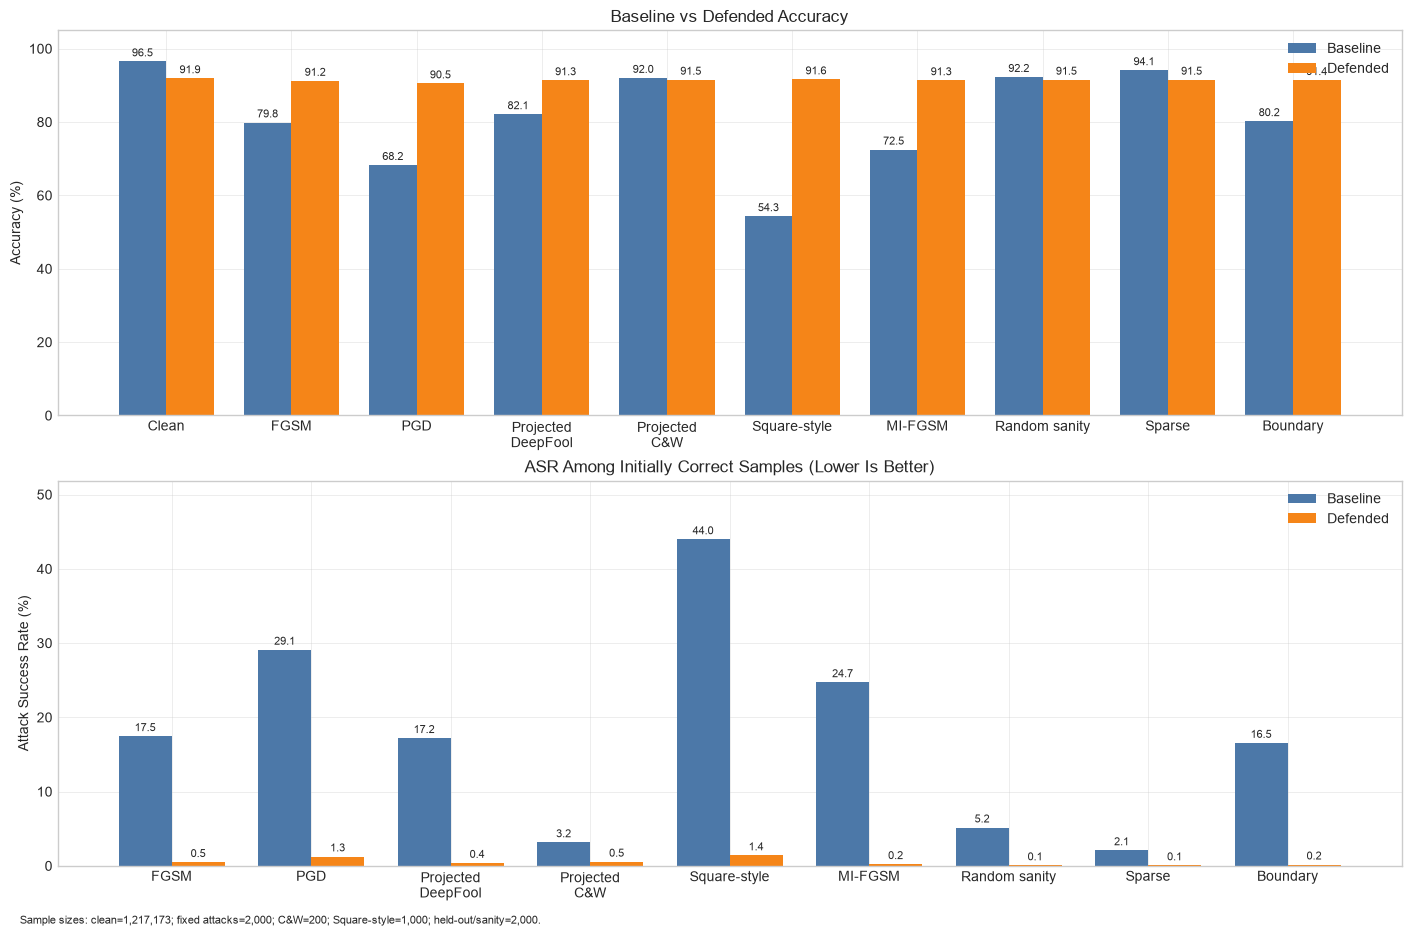

    . [09:17:48.74] Saved ./output/v7/seed_42\figures\01_attack_accuracy_and_asr.png


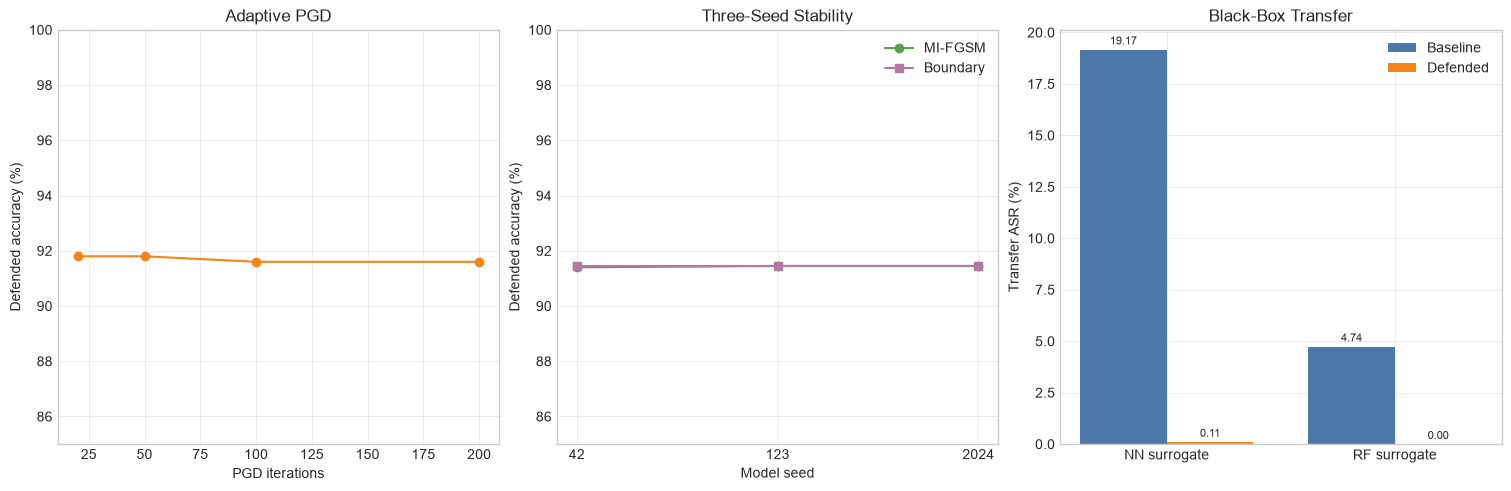

    . [09:17:49.50] Saved ./output/v7/seed_42\figures\02_adaptive_seed_transfer_validation.png


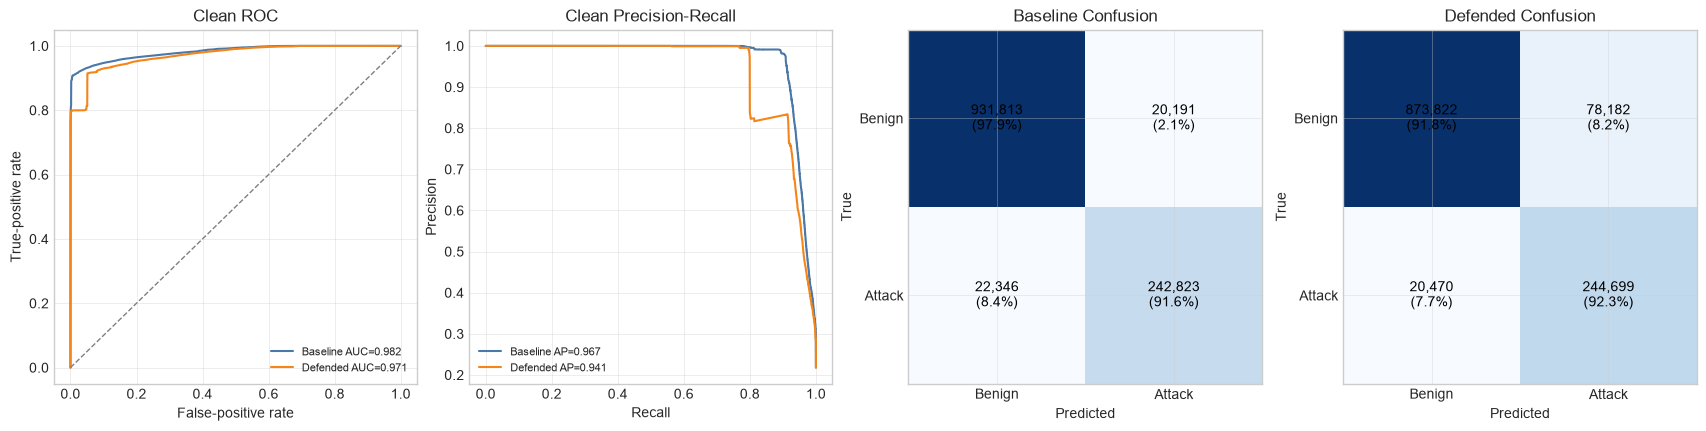

    . [09:17:55.39] Saved ./output/v7/seed_42\figures\03_clean_roc_pr_confusion.png


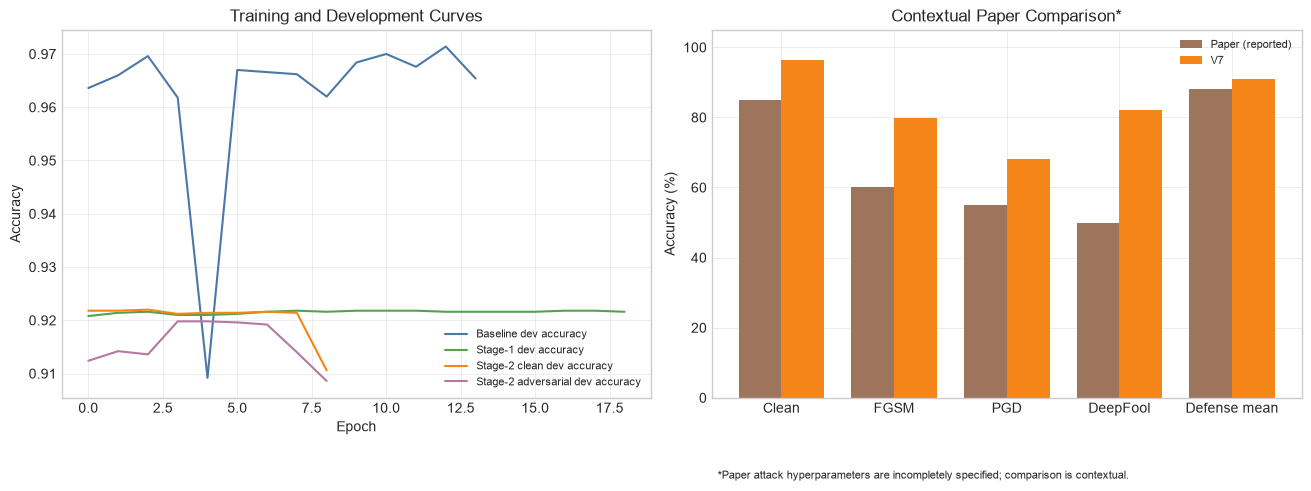

    . [09:17:56.04] Saved ./output/v7/seed_42\figures\04_training_and_paper_context.png


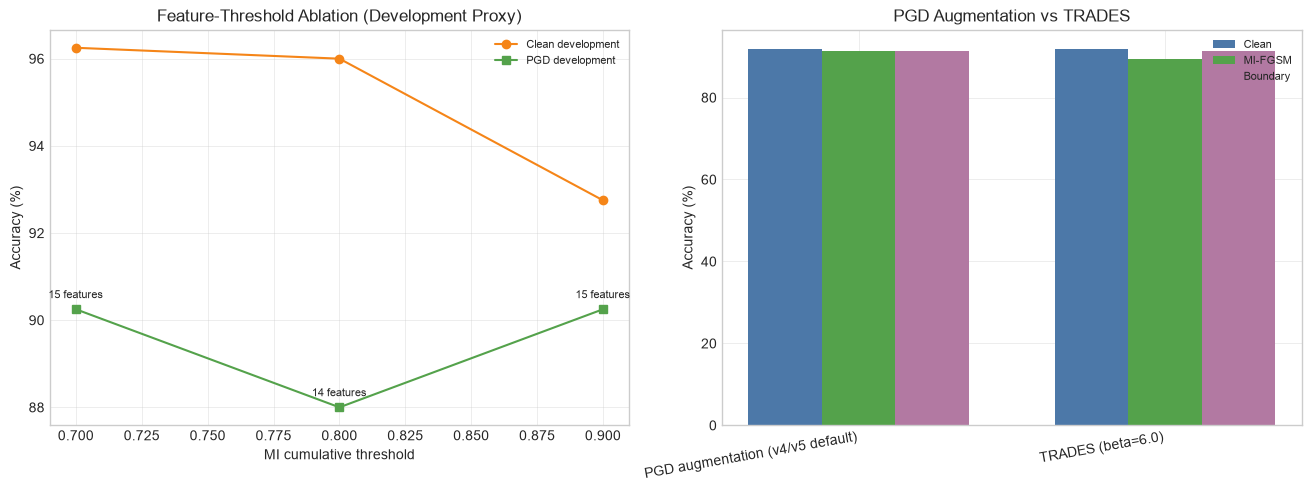

    . [09:17:56.63] Saved ./output/v7/seed_42\figures\05_feature_and_training_ablations.png

FINAL SUPERVISOR SUMMARY
                               Metric    Value              Unit
              Baseline clean accuracy  96.5053                 %
              Defended clean accuracy  91.8950                 %
                Clean-accuracy change  -4.6103 percentage points
     Defended clean balanced accuracy  92.0340                 %
                    Defended clean F1  83.2239                 %
                   Defended clean MCC   0.7861       coefficient
   Defended clean false-positive rate   8.2124                 %
      Defended FGSM/PGD/DeepFool mean  91.0167                 %
          Worst adaptive-PGD accuracy  91.6000                 %
              Three-seed MI-FGSM mean  91.4333                 %
Three-seed MI-FGSM standard deviation   0.0289 percentage points
            NN transfer ASR: baseline  19.1700                 %
            NN transfer ASR: defended

In [36]:
# ===== SECTION 37: final figures, supervisor summary, and validation =====
log.section("Final figures, supervisor summary, and validation")

FIGURE_DIR = os.path.join(OUTPUT_DIR, "figures")
os.makedirs(FIGURE_DIR, exist_ok=True)

def _save_figure(fig, filename):
    path = os.path.join(FIGURE_DIR, filename)
    fig.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    log.info(f"Saved {path}")
    return path

figure_paths = []
if CONFIG.get("generate_plots", True):
    plt.style.use("seaborn-v0_8-whitegrid")
    baseline_color = "#4C78A8"
    defended_color = "#F58518"

    # Figure 1: within-run accuracy and ASR. This is the primary fair comparison.
    attack_labels = [
        "Clean", "FGSM", "PGD", "Projected\nDeepFool", "Projected\nC&W",
        "Square-style", "MI-FGSM", "Random sanity", "Sparse", "Boundary",
    ]
    base_acc = [
        baseline_clean_metrics["accuracy"] * 100,
        adv_results_before["FGSM"]["accuracy"] * 100,
        adv_results_before["PGD"]["accuracy"] * 100,
        adv_results_before["DeepFool"]["accuracy"] * 100,
        adv_results_before["CW"]["accuracy"] * 100,
        square_before["accuracy"] * 100,
        unseen_results["MI-FGSM"]["baseline"]["accuracy"] * 100,
        unseen_results["Random"]["baseline"]["accuracy"] * 100,
        unseen_results["Sparse"]["baseline"]["accuracy"] * 100,
        unseen_results["Boundary-Search"]["baseline"]["accuracy"] * 100,
    ]
    def_acc = [
        defended_clean_metrics["accuracy"] * 100,
        adv_results_after["FGSM"]["accuracy"] * 100,
        adv_results_after["PGD"]["accuracy"] * 100,
        adv_results_after["DeepFool"]["accuracy"] * 100,
        adv_results_after["CW"]["accuracy"] * 100,
        square_after["accuracy"] * 100,
        unseen_results["MI-FGSM"]["defended"]["accuracy"] * 100,
        unseen_results["Random"]["defended"]["accuracy"] * 100,
        unseen_results["Sparse"]["defended"]["accuracy"] * 100,
        unseen_results["Boundary-Search"]["defended"]["accuracy"] * 100,
    ]
    base_asr = [
        adv_results_before[name]["success_rate"] * 100 for name in ["FGSM", "PGD", "DeepFool", "CW"]
    ] + [square_before["success_rate"] * 100] + [
        unseen_results[name]["baseline"]["success_rate"] * 100
        for name in ["MI-FGSM", "Random", "Sparse", "Boundary-Search"]
    ]
    def_asr = [
        adv_results_after[name]["success_rate"] * 100 for name in ["FGSM", "PGD", "DeepFool", "CW"]
    ] + [square_after["success_rate"] * 100] + [
        unseen_results[name]["defended"]["success_rate"] * 100
        for name in ["MI-FGSM", "Random", "Sparse", "Boundary-Search"]
    ]

    x = np.arange(len(attack_labels))
    width = 0.38
    fig, axes = plt.subplots(2, 1, figsize=(14, 9), constrained_layout=True)
    axes[0].bar(x - width/2, base_acc, width, label="Baseline", color=baseline_color)
    axes[0].bar(x + width/2, def_acc, width, label="Defended", color=defended_color)
    axes[0].set_ylabel("Accuracy (%)")
    axes[0].set_title("Baseline vs Defended Accuracy")
    axes[0].set_xticks(x, attack_labels)
    axes[0].set_ylim(0, 105)
    axes[0].legend()
    for container in axes[0].containers:
        axes[0].bar_label(container, fmt="%.1f", fontsize=8, padding=2)

    x_asr = np.arange(len(attack_labels) - 1)
    axes[1].bar(x_asr - width/2, base_asr, width, label="Baseline", color=baseline_color)
    axes[1].bar(x_asr + width/2, def_asr, width, label="Defended", color=defended_color)
    axes[1].set_ylabel("Attack Success Rate (%)")
    axes[1].set_title("ASR Among Initially Correct Samples (Lower Is Better)")
    axes[1].set_xticks(x_asr, attack_labels[1:])
    axes[1].set_ylim(0, max(10, max(base_asr + def_asr) * 1.18))
    axes[1].legend()
    for container in axes[1].containers:
        axes[1].bar_label(container, fmt="%.1f", fontsize=8, padding=2)
    fig.text(0.01, -0.02,
             f"Sample sizes: clean={len(y_test):,}; fixed attacks={N_ATTACK:,}; C&W={min(CONFIG['cw_n_samples'], N_ATTACK):,}; "
             f"Square-style={N_SQ:,}; held-out/sanity={N_UNSEEN:,}.", fontsize=8)
    figure_paths.append(_save_figure(fig, "01_attack_accuracy_and_asr.png"))

    # Figure 2: evidence that the result is stable under stronger attacks,
    # independent seeds and black-box transfer.
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), constrained_layout=True)
    axes[0].plot(table10["PGD iters"], table10["Defended Acc%"], marker="o", color=defended_color)
    axes[0].set_xlabel("PGD iterations")
    axes[0].set_ylabel("Defended accuracy (%)")
    axes[0].set_title("Adaptive PGD")
    axes[0].set_ylim(min(table10["Defended Acc%"].min() - 2, 85), 100)

    axes[1].plot(stability_table["Seed"].astype(str), stability_table["MI-FGSM Acc%"],
                 marker="o", label="MI-FGSM", color="#54A24B")
    axes[1].plot(stability_table["Seed"].astype(str), stability_table["BW Acc%"],
                 marker="s", label="Boundary", color="#B279A2")
    axes[1].set_xlabel("Model seed")
    axes[1].set_ylabel("Defended accuracy (%)")
    axes[1].set_title("Three-Seed Stability")
    axes[1].set_ylim(min(stability_table[["MI-FGSM Acc%", "BW Acc%"]].min().min() - 2, 85), 100)
    axes[1].legend()

    tr_x = np.arange(len(table11))
    axes[2].bar(tr_x - width/2, table11["Baseline Transfer ASR%"], width,
                label="Baseline", color=baseline_color)
    axes[2].bar(tr_x + width/2, table11["Defended Transfer ASR%"], width,
                label="Defended", color=defended_color)
    axes[2].set_xticks(tr_x, ["NN surrogate", "RF surrogate"])
    axes[2].set_ylabel("Transfer ASR (%)")
    axes[2].set_title("Black-Box Transfer")
    axes[2].legend()
    for container in axes[2].containers:
        axes[2].bar_label(container, fmt="%.2f", fontsize=8, padding=2)
    figure_paths.append(_save_figure(fig, "02_adaptive_seed_transfer_validation.png"))

    # Figure 3: clean ROC/PR curves and confusion matrices.
    base_probs = predict_proba_numpy(baseline_model, X_test, DEVICE)[:, 1]
    def_probs = predict_proba_numpy(defended_model, X_test_def, DEVICE)[:, 1]
    base_preds = (base_probs >= 0.5).astype(int)
    def_preds = (def_probs >= 0.5).astype(int)
    fpr_b, tpr_b, _ = roc_curve(y_test, base_probs)
    fpr_d, tpr_d, _ = roc_curve(y_test, def_probs)
    prec_b, rec_b, _ = precision_recall_curve(y_test, base_probs)
    prec_d, rec_d, _ = precision_recall_curve(y_test, def_probs)
    cm_b = confusion_matrix(y_test, base_preds)
    cm_d = confusion_matrix(y_test, def_preds)

    fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), constrained_layout=True)
    axes[0].plot(fpr_b, tpr_b, label=f"Baseline AUC={baseline_clean_metrics['roc_auc']:.3f}", color=baseline_color)
    axes[0].plot(fpr_d, tpr_d, label=f"Defended AUC={defended_clean_metrics['roc_auc']:.3f}", color=defended_color)
    axes[0].plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
    axes[0].set(xlabel="False-positive rate", ylabel="True-positive rate", title="Clean ROC")
    axes[0].legend(fontsize=8)
    axes[1].plot(rec_b, prec_b, label=f"Baseline AP={baseline_clean_metrics['pr_auc']:.3f}", color=baseline_color)
    axes[1].plot(rec_d, prec_d, label=f"Defended AP={defended_clean_metrics['pr_auc']:.3f}", color=defended_color)
    axes[1].set(xlabel="Recall", ylabel="Precision", title="Clean Precision-Recall")
    axes[1].legend(fontsize=8)
    for ax, cm, title in [(axes[2], cm_b, "Baseline Confusion"), (axes[3], cm_d, "Defended Confusion")]:
        image = ax.imshow(cm, cmap="Blues")
        for i in range(2):
            for j in range(2):
                row_pct = cm[i, j] / max(cm[i].sum(), 1) * 100
                ax.text(j, i, f"{cm[i, j]:,}\n({row_pct:.1f}%)", ha="center", va="center", color="black")
        ax.set_xticks([0, 1], ["Benign", "Attack"])
        ax.set_yticks([0, 1], ["Benign", "Attack"])
        ax.set(xlabel="Predicted", ylabel="True", title=title)
    figure_paths.append(_save_figure(fig, "03_clean_roc_pr_confusion.png"))

    # Figure 4: learning curves and contextual paper comparison.
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
    axes[0].plot(baseline_history["val_acc"], label="Baseline dev accuracy", color=baseline_color)
    axes[0].plot(stage1_history["val_acc"], label="Stage-1 dev accuracy", color="#54A24B")
    axes[0].plot(adv_train_history["val_acc"], label="Stage-2 clean dev accuracy", color=defended_color)
    axes[0].plot(adv_train_history["val_adv_acc"], label="Stage-2 adversarial dev accuracy", color="#B279A2")
    axes[0].set(xlabel="Epoch", ylabel="Accuracy", title="Training and Development Curves")
    axes[0].legend(fontsize=8)

    comparable_labels = ["Clean", "FGSM", "PGD", "DeepFool", "Defense mean"]
    paper_values = [85.0, 60.0, 55.0, 50.0, 88.0]
    v7_values = [
        baseline_clean_metrics["accuracy"] * 100,
        adv_results_before["FGSM"]["accuracy"] * 100,
        adv_results_before["PGD"]["accuracy"] * 100,
        adv_results_before["DeepFool"]["accuracy"] * 100,
        defended_known_mean,
    ]
    px = np.arange(len(comparable_labels))
    axes[1].bar(px - width/2, paper_values, width, label="Paper (reported)", color="#9D755D")
    axes[1].bar(px + width/2, v7_values, width, label="V7", color=defended_color)
    axes[1].set_xticks(px, comparable_labels)
    axes[1].set(ylabel="Accuracy (%)", title="Contextual Paper Comparison*")
    axes[1].set_ylim(0, 105)
    axes[1].legend(fontsize=8)
    axes[1].text(0.01, -0.22, "*Paper attack hyperparameters are incompletely specified; comparison is contextual.",
                 transform=axes[1].transAxes, fontsize=8)
    figure_paths.append(_save_figure(fig, "04_training_and_paper_context.png"))

    # Figure 5: feature-threshold and training-objective ablations.
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
    axes[0].plot(sweep_table["mi_threshold"], sweep_table["defended_dev_acc%"],
                 marker="o", label="Clean development", color=defended_color)
    axes[0].plot(sweep_table["mi_threshold"], sweep_table["defended_pgd_acc%"],
                 marker="s", label="PGD development", color="#54A24B")
    for _, row_value in sweep_table.iterrows():
        axes[0].annotate(f"{int(row_value['n_shap_features'])} features",
                         (row_value["mi_threshold"], row_value["defended_pgd_acc%"]),
                         textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
    axes[0].set(xlabel="MI cumulative threshold", ylabel="Accuracy (%)",
                title="Feature-Threshold Ablation (Development Proxy)")
    axes[0].legend(fontsize=8)

    method_x = np.arange(len(trades_comparison))
    ablation_width = 0.24
    for offset, column, label, color in [
        (-ablation_width, "Defended Clean%", "Clean", baseline_color),
        (0, "MI-FGSM Acc%", "MI-FGSM", "#54A24B"),
        (ablation_width, "BW Acc%", "Boundary", "#B279A2"),
    ]:
        axes[1].bar(method_x + offset, trades_comparison[column], ablation_width,
                    label=label, color=color)
    axes[1].set_xticks(method_x, trades_comparison["Method"], rotation=10, ha="right")
    axes[1].set(ylabel="Accuracy (%)", title="PGD Augmentation vs TRADES")
    axes[1].legend(fontsize=8)
    figure_paths.append(_save_figure(fig, "05_feature_and_training_ablations.png"))


# Persist learning histories so every curve can be reproduced without parsing the notebook.
pd.DataFrame({
    "epoch": np.arange(1, len(baseline_history["loss"]) + 1),
    "train_loss": baseline_history["loss"],
    "dev_loss": baseline_history["val_loss"],
    "dev_accuracy": baseline_history["val_acc"],
}).to_csv(f"{OUTPUT_DIR}/baseline_training_history.csv", index=False)
pd.DataFrame({
    "epoch": np.arange(1, len(stage1_history["loss"]) + 1),
    "train_loss": stage1_history["loss"],
    "dev_loss": stage1_history["val_loss"],
    "dev_accuracy": stage1_history["val_acc"],
}).to_csv(f"{OUTPUT_DIR}/stage1_training_history.csv", index=False)
pd.DataFrame({
    "epoch": np.arange(1, len(adv_train_history["loss"]) + 1),
    "train_loss": adv_train_history["loss"],
    "dev_loss": adv_train_history["val_loss"],
    "dev_accuracy": adv_train_history["val_acc"],
    "dev_adversarial_accuracy": adv_train_history["val_adv_acc"],
}).to_csv(f"{OUTPUT_DIR}/stage2_training_history.csv", index=False)

constraint_validation_table = pd.DataFrame(constraint_validation_records)
constraint_validation_table.to_csv(f"{OUTPUT_DIR}/constraint_validation.csv", index=False)

# Concise, data-derived supervisor table.
clean_delta_pp = (defended_clean_metrics["accuracy"] - baseline_clean_metrics["accuracy"]) * 100
adaptive_worst_acc = float(table10["Defended Acc%"].min())
supervisor_summary = pd.DataFrame([
    ("Baseline clean accuracy", baseline_clean_metrics["accuracy"] * 100, "%"),
    ("Defended clean accuracy", defended_clean_metrics["accuracy"] * 100, "%"),
    ("Clean-accuracy change", clean_delta_pp, "percentage points"),
    ("Defended clean balanced accuracy", defended_clean_metrics["balanced_accuracy"] * 100, "%"),
    ("Defended clean F1", defended_clean_metrics["f1"] * 100, "%"),
    ("Defended clean MCC", defended_clean_metrics["mcc"], "coefficient"),
    ("Defended clean false-positive rate", defended_clean_metrics["false_positive_rate"] * 100, "%"),
    ("Defended FGSM/PGD/DeepFool mean", defended_known_mean, "%"),
    ("Worst adaptive-PGD accuracy", adaptive_worst_acc, "%"),
    ("Three-seed MI-FGSM mean", stability_table["MI-FGSM Acc%"].mean(), "%"),
    ("Three-seed MI-FGSM standard deviation", stability_table["MI-FGSM Acc%"].std(), "percentage points"),
    ("NN transfer ASR: baseline", table11.iloc[0]["Baseline Transfer ASR%"], "%"),
    ("NN transfer ASR: defended", table11.iloc[0]["Defended Transfer ASR%"], "%"),
    ("Median minimum perturbation: baseline", minperturb_summary_baseline["median_min_eps"], "scaled L_inf"),
    ("Median minimum perturbation: defended", minperturb_summary_defended["median_min_eps"], "scaled L_inf"),
    ("Defense training overhead", overhead_defense_training_pct, "%"),
], columns=["Metric", "Value", "Unit"])
supervisor_summary["Value"] = pd.to_numeric(supervisor_summary["Value"]).round(4)
print_table("FINAL SUPERVISOR SUMMARY", supervisor_summary)
supervisor_summary.to_csv(f"{OUTPUT_DIR}/supervisor_summary.csv", index=False)

# Final integrity checks. Any failure stops the notebook and prevents a false
# "complete" message.
validation_checks = {
    **split_validation_checks,
    "arrays_finite": bool(np.isfinite(X_train_bal).all() and np.isfinite(X_dev).all() and np.isfinite(X_test).all()),
    "epsilon_consistent": bool(np.isclose(CONFIG["attack_eps"], CONFIG["adv_train_eps"]) and
                               np.isclose(CONFIG["attack_eps"], CONFIG["unseen_attack_eps"])),
    "known_attacks_complete": set(["FGSM", "PGD", "DeepFool", "CW"]).issubset(adv_results_after),
    "no_uncapped_cw_reported": "CW_uncapped" not in adv_results_before and "CW_uncapped" not in adv_results_after,
    "unseen_attacks_complete": set(["MI-FGSM", "Random", "Sparse", "Boundary-Search"]).issubset(unseen_results),
    "adaptive_grid_complete": set(table10["PGD iters"]) == set(CONFIG["adaptive_pgd_iters_grid"]),
    "stability_seeds_complete": set(stability_table["Seed"]) == set(CONFIG["stability_seeds"]),
    "transfer_rows_complete": len(table11) == 2,
    "all_bounded_known_attacks_valid": all(
        adv_results_after[name]["max_linf"] <= CONFIG["attack_eps"] + 1e-5
        and adv_results_before[name]["max_linf"] <= CONFIG["attack_eps"] + 1e-5
        for name in ["FGSM", "PGD", "DeepFool", "CW"]
    ),
    "featurewise_bounds_valid": bool(np.all(clip_values[0] < clip_values[1])),
    "robust_features_valid": bool(robust_features and set(robust_features).issubset(selected_features)),
    "attack_constraints_recorded": bool(len(constraint_validation_table) >= 20 and
                                          constraint_validation_table["passed"].all()),
    "figures_created": (not CONFIG.get("generate_plots", True)) or len(figure_paths) == 5,
    "summary_metrics_finite": bool(np.isfinite(supervisor_summary["Value"]).all()),
}

failed_checks = [name for name, passed in validation_checks.items() if not passed]
if failed_checks:
    raise AssertionError(f"Final validation failed: {failed_checks}")

with open(f"{OUTPUT_DIR}/final_validation.json", "w") as f:
    json.dump({"passed": True, "checks": validation_checks}, f, indent=2, cls=NumpyEncoder)

expected_artifacts = [
    "all_metrics.json", "run_config.json", "selected_features.json",
    "table4.csv", "table4_operational.csv", "table5.csv", "table6.csv", "table_minperturb.csv",
    "unseen_attack_table.csv", "paper_crosscheck.csv", "trades_comparison.csv",
    "table10_adaptive.csv", "stability_table.csv", "table11_transferability.csv",
    "v7_analysis_results.json", "v7_unified_synthesis.json",
    "supervisor_summary.csv", "constraint_validation.csv",
    "baseline_training_history.csv", "stage1_training_history.csv", "stage2_training_history.csv",
    "shap_feature_scores.csv", "final_validation.json",
]
missing_artifacts = [name for name in expected_artifacts
                     if not os.path.exists(os.path.join(OUTPUT_DIR, name))]
if missing_artifacts:
    raise AssertionError(f"Expected artifacts are missing: {missing_artifacts}")

v7_manifest = {
    "timestamp": datetime.now().isoformat(),
    "version": "v7_supervisor_final",
    "seed": SEED,
    "data_seed": DATA_SEED,
    "device": str(DEVICE),
    "output_dir": OUTPUT_DIR,
    "claim_scope": "within-dataset adversarial attack-algorithm generalization",
    "validation_passed": True,
    "artifacts": expected_artifacts,
    "figures": [os.path.relpath(path, OUTPUT_DIR) for path in figure_paths],
}
with open(f"{OUTPUT_DIR}/v7_manifest.json", "w") as f:
    json.dump(v7_manifest, f, indent=2, cls=NumpyEncoder)

log.ok("FINAL VALIDATION PASSED: all required metrics, attacks, seeds, budgets, figures, and artifacts are complete.")
log.ok("V7 supervisor-final run completed successfully.")
